In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
from pathlib import Path

root = Path("/kaggle/input")

print("Session is working!")
print("Mounted datasets:")

for p in sorted(root.iterdir()):
    print(p.name)

Session is working!
Mounted datasets:


In [1]:
%pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 81.8 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
from roboflow import Roboflow
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
api_key = secrets.get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)
project = rf.workspace("sayed-gamall").project(
    "fire-smoke-detection-yolov11"
)

dataset = project.version(2).download("yolov11")

print("Dataset downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fire-Smoke-Detection-Yolov11-2 in yolov11:: 100%|██████████| 20938/20938 [00:02<00:00, 9635.25it/s] 

Dataset downloaded to: /kaggle/working/Fire-Smoke-Detection-Yolov11-2


In [4]:
from pathlib import Path

data_dir = Path(dataset.location)

print("Dataset path:", data_dir)
print("\nTop-level contents:")
for p in sorted(data_dir.iterdir()):
    print(p.name)

yaml_file = data_dir / "data.yaml"
if yaml_file.exists():
    print("\n--- data.yaml ---")
    print(yaml_file.read_text())

Dataset path: /kaggle/working/Fire-Smoke-Detection-Yolov11-2

Top-level contents:
README.dataset.txt
README.roboflow.txt
data.yaml
test
train
valid

--- data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Fire', 'Smoke']

roboflow:
  workspace: sayed-gamal-kn2wu
  project: fire-smoke-detection-yolov11
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/sayed-gamal-kn2wu/fire-smoke-detection-yolov11/dataset/2


In [5]:
from pathlib import Path
from collections import Counter
import yaml

DATA_DIR = Path("/kaggle/working/Fire-Smoke-Detection-Yolov11-2")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Read dataset configuration
yaml_path = DATA_DIR / "data.yaml"
config = yaml.safe_load(yaml_path.read_text())

print("Dataset:", DATA_DIR)
print("Classes:", config.get("names"))
print("Number of classes:", config.get("nc"))

total_images = 0
total_labels = 0
all_class_counts = Counter()
issues = []

for split in ["train", "valid", "test"]:
    image_dir = DATA_DIR / split / "images"
    label_dir = DATA_DIR / split / "labels"

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )
    labels = sorted(label_dir.glob("*.txt")) if label_dir.exists() else []

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems

    class_counts = Counter()
    invalid_rows = []
    invalid_classes = []
    invalid_boxes = []
    empty_labels = 0

    for label_file in labels:
        lines = label_file.read_text().splitlines()

        if not lines:
            empty_labels += 1

        for line_num, line in enumerate(lines, start=1):
            parts = line.split()

            if len(parts) != 5:
                invalid_rows.append((label_file.name, line_num, line))
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                invalid_rows.append((label_file.name, line_num, line))
                continue

            class_counts[class_id] += 1

            if not (0 <= class_id < config["nc"]):
                invalid_classes.append((label_file.name, class_id))

            if not (
                0 <= x <= 1 and 0 <= y <= 1
                and 0 < w <= 1 and 0 < h <= 1
            ):
                invalid_boxes.append((label_file.name, line_num, x, y, w, h))

    total_images += len(images)
    total_labels += len(labels)
    all_class_counts.update(class_counts)

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without matching labels:", len(missing_labels))
    print("Labels without matching images:", len(orphan_labels))
    print("Empty label files:", empty_labels)
    print("Objects by class ID:", dict(class_counts))
    print("Malformed annotation rows:", len(invalid_rows))
    print("Invalid class IDs:", len(invalid_classes))
    print("Invalid box coordinates:", len(invalid_boxes))

    if missing_labels:
        print("Example images without labels:", list(missing_labels)[:5])
    if orphan_labels:
        print("Example orphan labels:", list(orphan_labels)[:5])

    issues.extend(
        [(split, "malformed row", x) for x in invalid_rows[:5]]
        + [(split, "invalid class", x) for x in invalid_classes[:5]]
        + [(split, "invalid box", x) for x in invalid_boxes[:5]]
    )

print("\n========== OVERALL ==========")
print("Total images:", total_images)
print("Total label files:", total_labels)
print("Total objects by class ID:", dict(all_class_counts))
print("Issues found:", len(issues))
print("Class-name mapping:", config.get("names"))

Dataset: /kaggle/working/Fire-Smoke-Detection-Yolov11-2
Classes: ['Fire', 'Smoke']
Number of classes: 2

--- TRAIN ---
Images: 9156
Label files: 9156
Images without matching labels: 0
Labels without matching images: 0
Empty label files: 4
Objects by class ID: {1: 3901, 0: 11505}
Malformed annotation rows: 411
Invalid class IDs: 0
Invalid box coordinates: 0

--- VALID ---
Images: 872
Label files: 872
Images without matching labels: 0
Labels without matching images: 0
Empty label files: 0
Objects by class ID: {1: 375, 0: 1137}
Malformed annotation rows: 25
Invalid class IDs: 0
Invalid box coordinates: 0

--- TEST ---
Images: 435
Label files: 435
Images without matching labels: 0
Labels without matching images: 0
Empty label files: 0
Objects by class ID: {1: 205, 0: 544}
Malformed annotation rows: 11
Invalid class IDs: 0
Invalid box coordinates: 0

========== OVERALL ==========
Total images: 10463
Total label files: 10463
Total objects by class ID: {1: 4481, 0: 13186}
Issues found: 15
Cla

In [6]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
from random import Random
from IPython.display import display
from PIL import Image
from ultralytics.utils.plotting import Annotator, colors

train_images = sorted(
    p for p in (DATA_DIR / "train" / "images").rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

rng = Random(42)
samples = rng.sample(train_images, min(3, len(train_images)))
class_names = config["names"]

for image_path in samples:
    label_path = DATA_DIR / "train" / "labels" / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    annotator = Annotator(image.copy())
    W, H = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            x1 = (x - w / 2) * W
            y1 = (y - h / 2) * H
            x2 = (x + w / 2) * W
            y2 = (y + h / 2) * H

            name = class_names[cls] if isinstance(class_names, list) else class_names.get(cls, str(cls))
            annotator.box_label(
                [x1, y1, x2, y2],
                name,
                color=colors(cls, True)
            )

    print(image_path.name)
    display(annotator.result())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
IMG_3682-1-_jpeg_jpg.rf.c827ebce71e6575787c4419cfed9909b.jpg


array([[[127, 127, 127],
        [133, 133, 133],
        [121, 121, 121],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]],

       [[124, 124, 124],
        [136, 136, 136],
        [134, 134, 134],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]],

       [[138, 138, 138],
        [117, 117, 117],
        [130, 130, 130],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]],

       ...,

       [[129, 129, 129],
        [129, 129, 129],
        [129, 129, 129],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]],

       [[129, 129, 129],
        [129, 129, 129],
        [129, 129, 129],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]],

       [[129, 129, 129],
        [129, 129, 129],
        [129, 129, 129],
        ...,
        [129, 129, 129],
        [129, 129, 129],
        [129, 129, 129]]

-a-e-c53799_png.rf.c7fa41286d966e55b88d7ab469d1d49a.jpg


array([[[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       ...,

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        ...,
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]]], dtype=uint8)

Img_1703_jpg.rf.0e35e1b4a2ef32cfc2fe8a24386d43ee.jpg


array([[[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [ 5,  5,  5],
        [22, 22, 22],
        [10, 10, 10]],

       [[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [ 4,  4,  4],
        [15, 15, 15],
        [29, 29, 29]],

       [[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [30, 30, 30],
        [11, 11, 11],
        [14, 14, 14]],

       ...,

       [[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [15, 15, 15],
        [15, 15, 15],
        [15, 15, 15]],

       [[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [15, 15, 15],
        [15, 15, 15],
        [15, 15, 15]],

       [[15, 15, 15],
        [15, 15, 15],
        [15, 15, 15],
        ...,
        [15, 15, 15],
        [15, 15, 15],
        [15, 15, 15]]], dtype=uint8)

In [8]:
from pathlib import Path
from collections import Counter, defaultdict

splits = ["train", "valid", "test"]
format_counts = defaultdict(Counter)
examples = defaultdict(list)

for split in splits:
    label_dir = DATA_DIR / split / "labels"

    for label_file in sorted(label_dir.glob("*.txt")):
        for line_no, line in enumerate(
            label_file.read_text(errors="replace").splitlines(), start=1
        ):
            parts = line.split()

            # Standard YOLO detection labels have 5 fields:
            # class_id, x_center, y_center, width, height
            if len(parts) != 5:
                format_counts[split][len(parts)] += 1

                if len(examples[split]) < 12:
                    examples[split].append({
                        "file": label_file.name,
                        "line": line_no,
                        "columns": len(parts),
                        "text": line[:250]
                    })

print("Column-count distribution for malformed rows:")
for split in splits:
    print(f"\n{split.upper()}: {dict(format_counts[split])}")
    for item in examples[split]:
        print(item)

Column-count distribution for malformed rows:

TRAIN: {11: 173, 15: 69, 19: 74, 17: 23, 13: 69, 37: 2, 35: 1}
{'file': 'H_00010_png_jpg.rf.7af2aa83759c37ce371e10e3a2d65755.txt', 'line': 1, 'columns': 11, 'text': '1 0.915625 0.05 0.0765625 0.05 0.0765625 0.8984375 0.915625 0.8984375 0.915625 0.05'}
{'file': 'H_00010_png_jpg.rf.a1024ae115042785c03b14d995786c6b.txt', 'line': 1, 'columns': 15, 'text': '1 0.854013925 1 0.9425008343749999 0.16154299218749998 0.039534918749999995 0.024469696875 0 0.3990825203125 0 0.960704475 0.2588580078125 1 0.854013925 1'}
{'file': 'H_00010_png_jpg.rf.d242ea0f582f89f26d83bc069280ff0f.txt', 'line': 1, 'columns': 19, 'text': '1 0.7620635 1 0.9656995765625 0.5934940703125 0.9845327125000001 0.299607040625 0.43138281718749993 0.0251251875 0.26958082499999997 0.0157012953125 0 0.5538485921875 0 0.7882191359374999 0.4267916484375 1 0.7620635 1'}
{'file': 'H_00015_png_jpg.rf.575a6ba4ff5527afd392aa44d2e49bef.txt', 'line': 1, 'columns': 19, 'text': '1 0.38607943749

In [9]:
from pathlib import Path
from collections import Counter

format_counts = Counter()
class_counts = Counter()
bad_rows = []

for split in ["train", "valid", "test"]:
    label_dir = DATA_DIR / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        for line_no, line in enumerate(
            label_file.read_text().splitlines(), start=1
        ):
            parts = line.split()
            if not parts:
                continue

            try:
                cls = int(parts[0])
                coords = list(map(float, parts[1:]))
            except ValueError:
                bad_rows.append((split, label_file.name, line_no, line))
                continue

            class_counts[(split, cls)] += 1

            if len(coords) == 4:
                format_counts[(split, "bbox")] += 1
            elif len(coords) >= 6 and len(coords) % 2 == 0:
                format_counts[(split, "polygon_candidate")] += 1
            else:
                format_counts[(split, "other")] += 1
                bad_rows.append((split, label_file.name, line_no, line))

print("Annotation format counts:")
for key, value in sorted(format_counts.items()):
    print(key, value)

print("\nClass counts:")
for key, value in sorted(class_counts.items()):
    print(key, value)

print("\nRows requiring further inspection:", len(bad_rows))
for row in bad_rows[:10]:
    print(row)

Annotation format counts:
('test', 'bbox') 749
('test', 'polygon_candidate') 11
('train', 'bbox') 15406
('train', 'polygon_candidate') 411
('valid', 'bbox') 1512
('valid', 'polygon_candidate') 25

Class counts:
('test', 0) 544
('test', 1) 216
('train', 0) 11505
('train', 1) 4312
('valid', 0) 1137
('valid', 1) 400

Rows requiring further inspection: 0


In [10]:
from pathlib import Path
from collections import Counter
import shutil
import yaml

SRC = DATA_DIR
DST = Path("/kaggle/working/Fire-Smoke-Detection-YOLO-detection")

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True)

config = yaml.safe_load((SRC / "data.yaml").read_text())
class_names = config["names"]
num_classes = config["nc"]

stats = Counter()
problems = []

for split in ["train", "valid", "test"]:
    src_images = SRC / split / "images"
    src_labels = SRC / split / "labels"
    dst_images = DST / split / "images"
    dst_labels = DST / split / "labels"

    dst_images.mkdir(parents=True)
    dst_labels.mkdir(parents=True)

    # Copy image files unchanged
    for image_path in src_images.rglob("*"):
        if image_path.is_file():
            shutil.copy2(image_path, dst_images / image_path.name)

    for label_path in src_labels.glob("*.txt"):
        converted = []

        for line_no, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()
            if not parts:
                continue

            try:
                cls = int(parts[0])
                coords = list(map(float, parts[1:]))
            except ValueError:
                problems.append((split, label_path.name, line_no, "non-numeric"))
                continue

            if not (0 <= cls < num_classes):
                problems.append((split, label_path.name, line_no, "invalid class"))
                continue

            if len(coords) == 4:
                # Existing YOLO bbox: x_center, y_center, width, height
                xc, yc, w, h = coords
                if not (
                    0 <= xc <= 1 and 0 <= yc <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                ):
                    problems.append((split, label_path.name, line_no, "invalid bbox"))
                    continue

            elif len(coords) >= 6 and len(coords) % 2 == 0:
                # Polygon: x1,y1,x2,y2,...
                xs = coords[0::2]
                ys = coords[1::2]

                if any(not (0 <= v <= 1) for v in coords):
                    problems.append((split, label_path.name, line_no, "invalid polygon"))
                    continue

                xmin, xmax = min(xs), max(xs)
                ymin, ymax = min(ys), max(ys)

                xc = (xmin + xmax) / 2
                yc = (ymin + ymax) / 2
                w = xmax - xmin
                h = ymax - ymin

                if w <= 0 or h <= 0:
                    problems.append((split, label_path.name, line_no, "zero-area polygon"))
                    continue

                stats[(split, "polygon_converted")] += 1

            else:
                problems.append((split, label_path.name, line_no, "unexpected format"))
                continue

            converted.append(
                f"{cls} {xc:.8f} {yc:.8f} {w:.8f} {h:.8f}"
            )
            stats[(split, "valid_objects")] += 1

        # Preserve empty label files too
        (dst_labels / label_path.name).write_text(
            "\n".join(converted) + ("\n" if converted else "")
        )

# Write corrected config with paths relative to the dataset root
out_config = {
    "path": str(DST),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": num_classes,
    "names": class_names,
}

(DST / "data.yaml").write_text(yaml.safe_dump(out_config, sort_keys=False))

print("Output dataset:", DST)
print("\nConversion statistics:")
for key, value in sorted(stats.items()):
    print(key, value)

print("\nProblems:", len(problems))
for item in problems[:20]:
    print(item)

print("\nGenerated YAML:")
print((DST / "data.yaml").read_text())

Output dataset: /kaggle/working/Fire-Smoke-Detection-YOLO-detection

Conversion statistics:
('test', 'polygon_converted') 11
('test', 'valid_objects') 760
('train', 'polygon_converted') 411
('train', 'valid_objects') 15817
('valid', 'polygon_converted') 25
('valid', 'valid_objects') 1537

Problems: 0

Generated YAML:
path: /kaggle/working/Fire-Smoke-Detection-YOLO-detection
train: train/images
val: valid/images
test: test/images
nc: 2
names:
- Fire
- Smoke



In [11]:
from pathlib import Path
from collections import Counter

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
validation = Counter()
errors = []

for split in ["train", "valid", "test"]:
    image_dir = DST / split / "images"
    label_dir = DST / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = list(label_dir.glob("*.txt"))

    validation[(split, "images")] = len(images)
    validation[(split, "labels")] = len(labels)

    if {p.stem for p in images} != {p.stem for p in labels}:
        errors.append((split, "image-label filename mismatch"))

    for label_file in labels:
        for line_no, line in enumerate(label_file.read_text().splitlines(), 1):
            parts = line.split()

            if len(parts) != 5:
                errors.append((split, label_file.name, line_no, "not 5 fields"))
                continue

            try:
                cls = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])
            except ValueError:
                errors.append((split, label_file.name, line_no, "parse failure"))
                continue

            if not (0 <= cls < num_classes):
                errors.append((split, label_file.name, line_no, "invalid class"))

            if not (
                0 <= xc <= 1 and 0 <= yc <= 1
                and 0 < w <= 1 and 0 < h <= 1
            ):
                errors.append((split, label_file.name, line_no, "invalid bbox"))

print("Counts:")
for key, value in sorted(validation.items()):
    print(key, value)

print("\nValidation errors:", len(errors))
for error in errors[:20]:
    print(error)

assert not errors, "Fix validation errors before training."
print("\nPASS: converted dataset passed structural validation.")

Counts:
('test', 'images') 435
('test', 'labels') 435
('train', 'images') 9156
('train', 'labels') 9156
('valid', 'images') 872
('valid', 'labels') 872

Validation errors: 0

PASS: converted dataset passed structural validation.


In [12]:
import os
import random
import numpy as np
import torch
from pathlib import Path
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_YAML = "/kaggle/working/Fire-Smoke-Detection-YOLO-detection/data.yaml"
PROJECT_DIR = "/kaggle/working/fire_smoke_yolo11"

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset YAML exists:", Path(DATA_YAML).exists())
print("Dataset config:\n", Path(DATA_YAML).read_text())

# Start with the small pretrained YOLO11 detector.
MODEL_NAME = "yolo11n.pt"
IMG_SIZE = 640
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
EPOCHS = 50

print("\nModel:", MODEL_NAME)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)
print("Output directory:", PROJECT_DIR)

CUDA available: True
GPU: Tesla T4
Dataset YAML exists: True
Dataset config:
 path: /kaggle/working/Fire-Smoke-Detection-YOLO-detection
train: train/images
val: valid/images
test: test/images
nc: 2
names:
- Fire
- Smoke


Model: yolo11n.pt
Image size: 640
Batch size: 16
Maximum epochs: 50
Output directory: /kaggle/working/fire_smoke_yolo11


In [13]:
model = YOLO(MODEL_NAME)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=0 if torch.cuda.is_available() else "cpu",
    seed=SEED,
    deterministic=True,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    patience=8,
    workers=4,
    project=PROJECT_DIR,
    name="yolo11n_fire_smoke",
    exist_ok=True,
    save=True,
    plots=True,
    verbose=True
)

print("Training finished.")
print("Best checkpoint:", model.trainer.best)
print("Last checkpoint:", model.trainer.last)
print("Results directory:", model.trainer.save_dir)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Fire-Smoke-Detection-YOLO-detection/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_fire_smoke, nbs=64,

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      2.76G      1.686      2.094      1.865         12        640: 100% ━━━━━━━━━━━━ 573/573 8.4it/s 1:080.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 6.1it/s 4.6s0.2s
                   all        872       1516      0.534      0.438      0.436      0.192

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.76G      1.657      2.028      1.841         10        640: 100% ━━━━━━━━━━━━ 573/573 8.6it/s 1:070.1sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 6.5it/s 4.3s0.1s
                   all        872       1516      0.556      0.441      0.471       0.24

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.76G       1.61      1.966      1.812         21        640: 100% ━━━━━━━━━━━━ 573/573 8.5it/s 1:070.2sss
                 Class     Ima

In [14]:
from pathlib import Path
from ultralytics import YOLO
import torch
import json

DATA_YAML = (
    "/kaggle/working/"
    "Fire-Smoke-Detection-YOLO-detection/data.yaml"
)

BEST_MODEL = (
    "/kaggle/working/fire_smoke_yolo11/"
    "yolo11n_fire_smoke/weights/best.pt"
)

assert Path(DATA_YAML).exists(), "Dataset YAML not found"
assert Path(BEST_MODEL).exists(), "Best model checkpoint not found"

device = 0 if torch.cuda.is_available() else "cpu"
batch_size = 16 if torch.cuda.is_available() else 4

test_model = YOLO(BEST_MODEL)

test_results = test_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=batch_size,
    device=device,
    plots=True,
    project="/kaggle/working/fire_smoke_yolo11",
    name="test_evaluation",
    exist_ok=True
)

metrics = {
    "precision": float(test_results.box.mp),
    "recall": float(test_results.box.mr),
    "mAP50": float(test_results.box.map50),
    "mAP50_95": float(test_results.box.map),
}

print("Held-out test metrics:")
print(json.dumps(metrics, indent=2))

metrics_path = Path(
    "/kaggle/working/fire_smoke_yolo11/"
    "test_evaluation/test_metrics.json"
)
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(metrics, indent=2))

print("Metrics saved to:", metrics_path)
print("Test plots saved in:", metrics_path.parent)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1212.8±472.6 MB/s, size: 41.0 KB)
val: Scanning /kaggle/working/Fire-Smoke-Detection-YOLO-detection/test/labels... 435 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 435/435 1.3Kit/s 0.3s<0.1s
val: /kaggle/working/Fire-Smoke-Detection-YOLO-detection/test/images/Img_1039_jpg.rf.6c174491ecb5b2ab7c968c49ed4918ea.jpg: 1 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-YOLO-detection/test/images/Img_1166_jpg.rf.d71ad2b922967dbb6ee59be88f618980.jpg: 4 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-YOLO-detection/test/images/Img_1196_jpg.rf.4c8c7963afdb2c3759b4ae188042cc54.jpg: 1 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-YOLO-detection/test/images/Img_423_jpg.rf.949f27f164200f50a2abf8a51f72487c.jpg: 2 duplicate l

Available evaluation artifacts:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
test_metrics.json
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

confusion_matrix.png


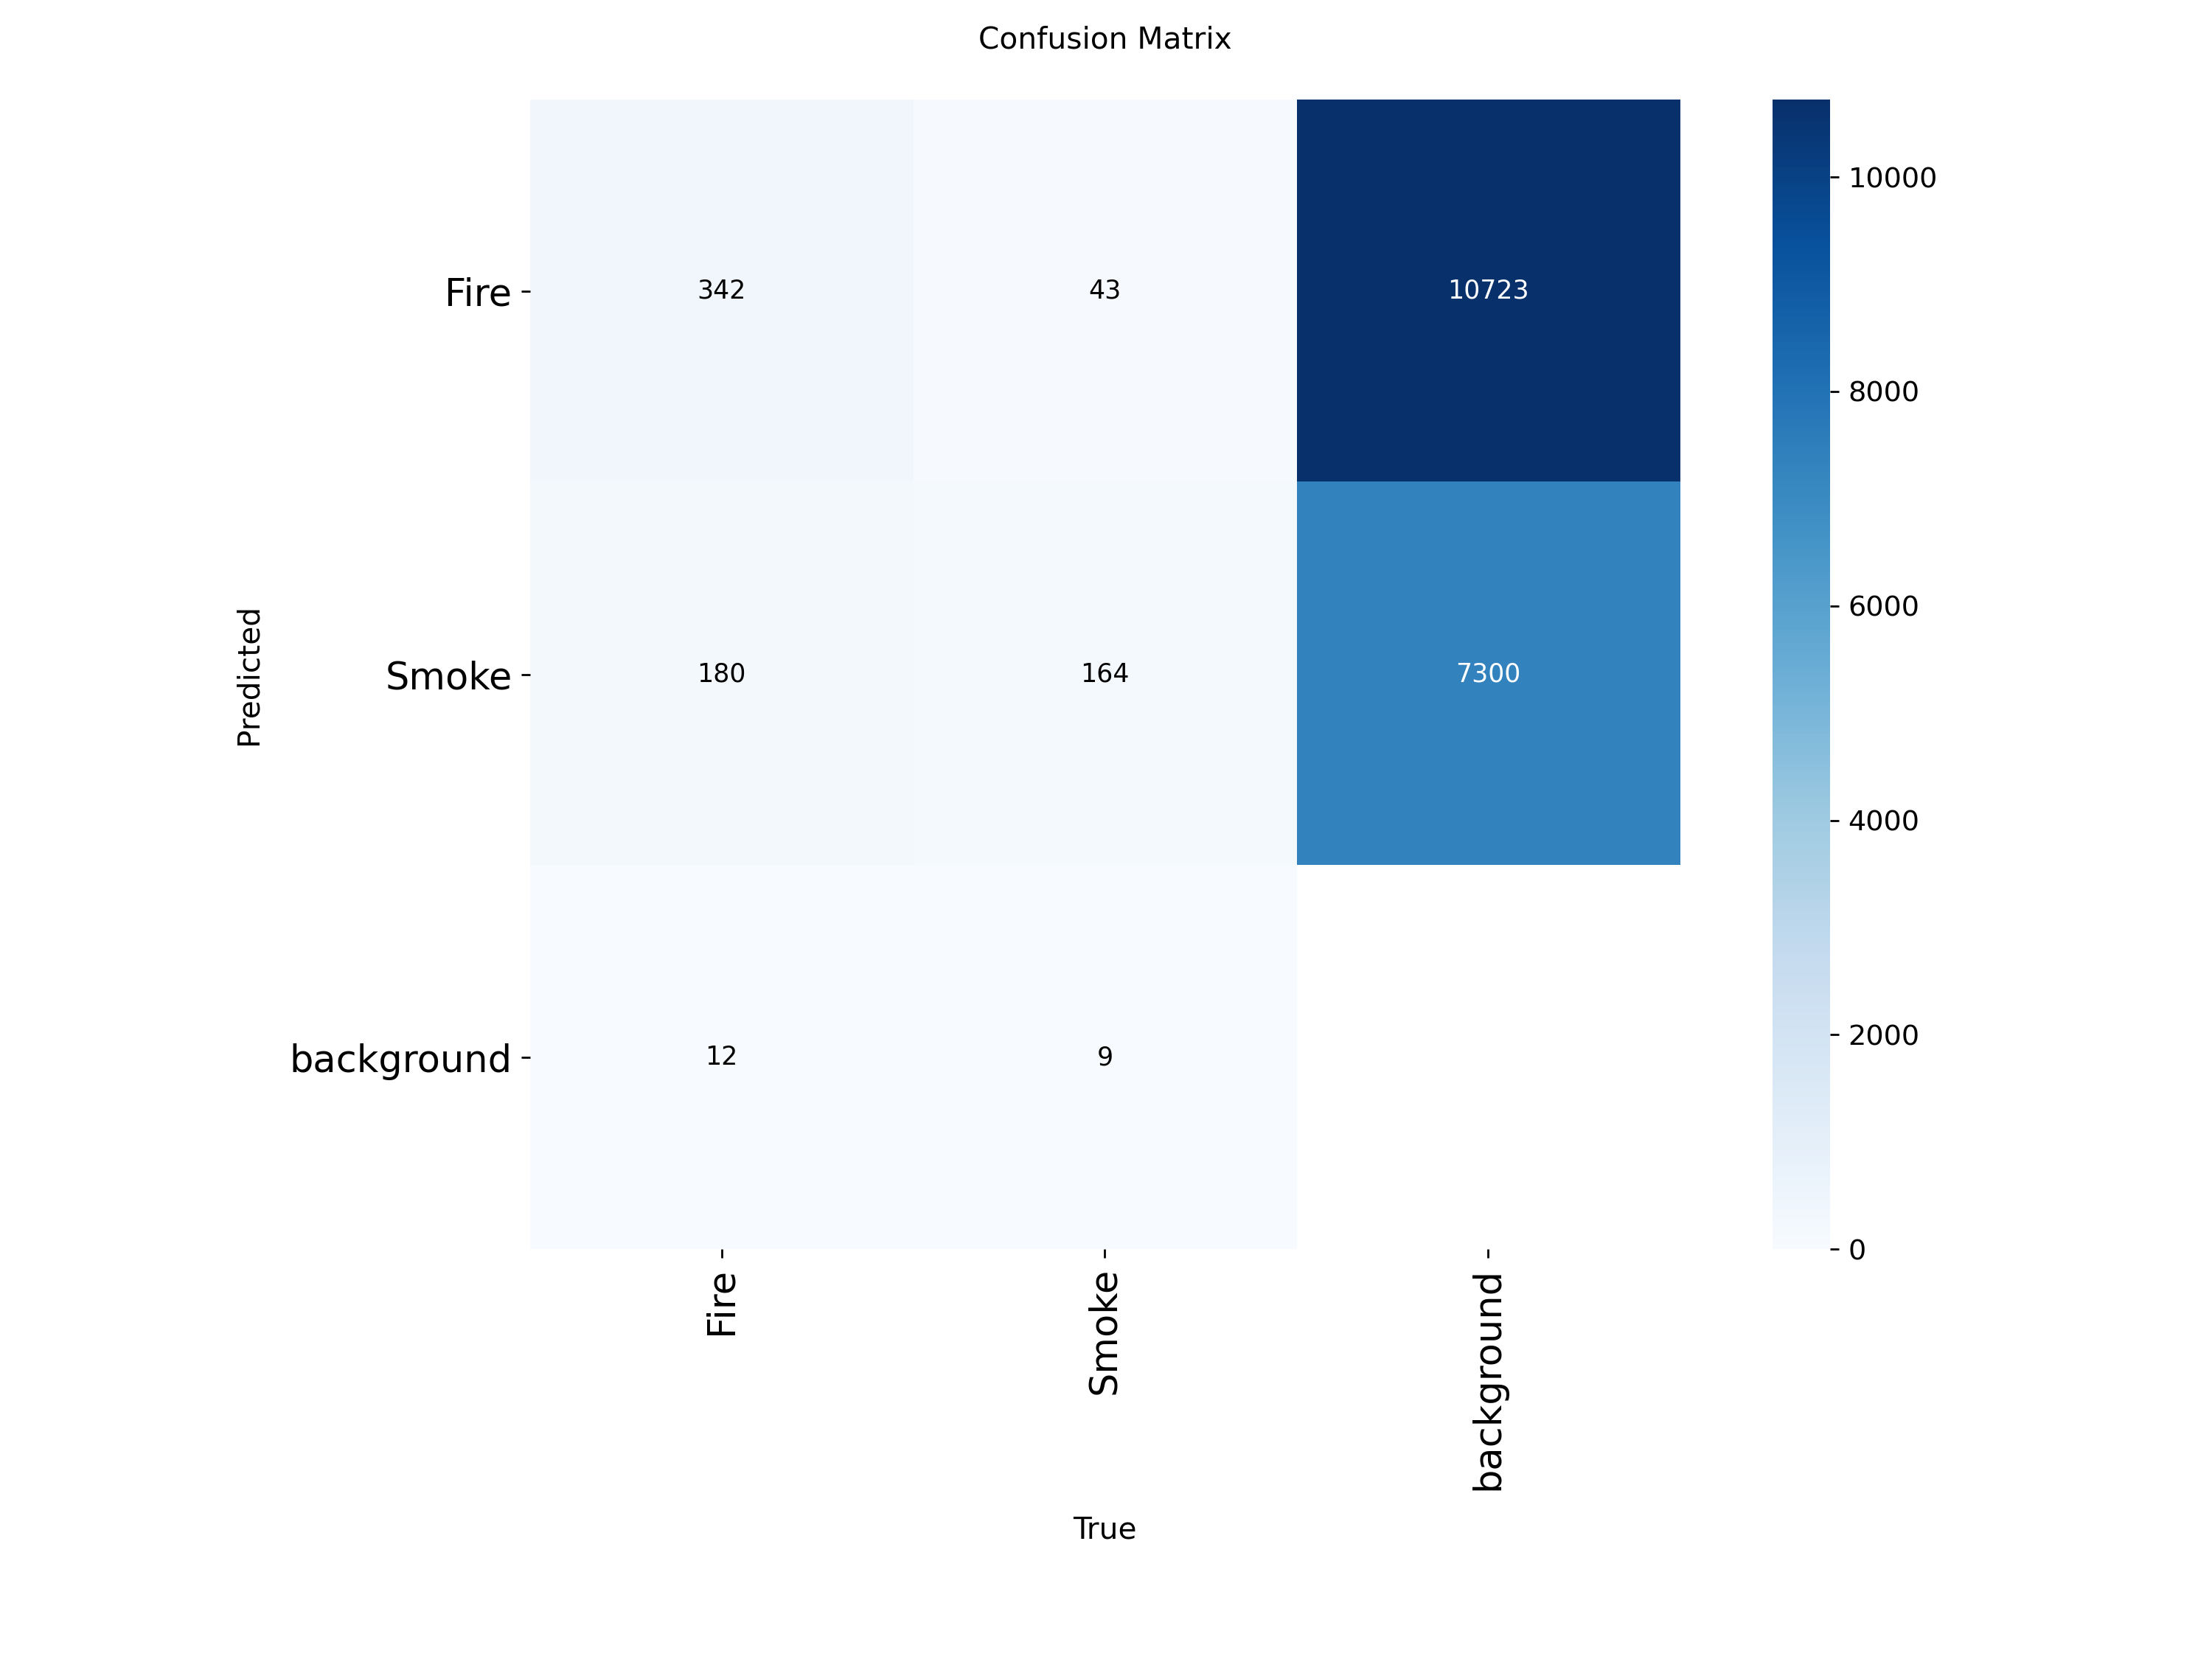


confusion_matrix_normalized.png


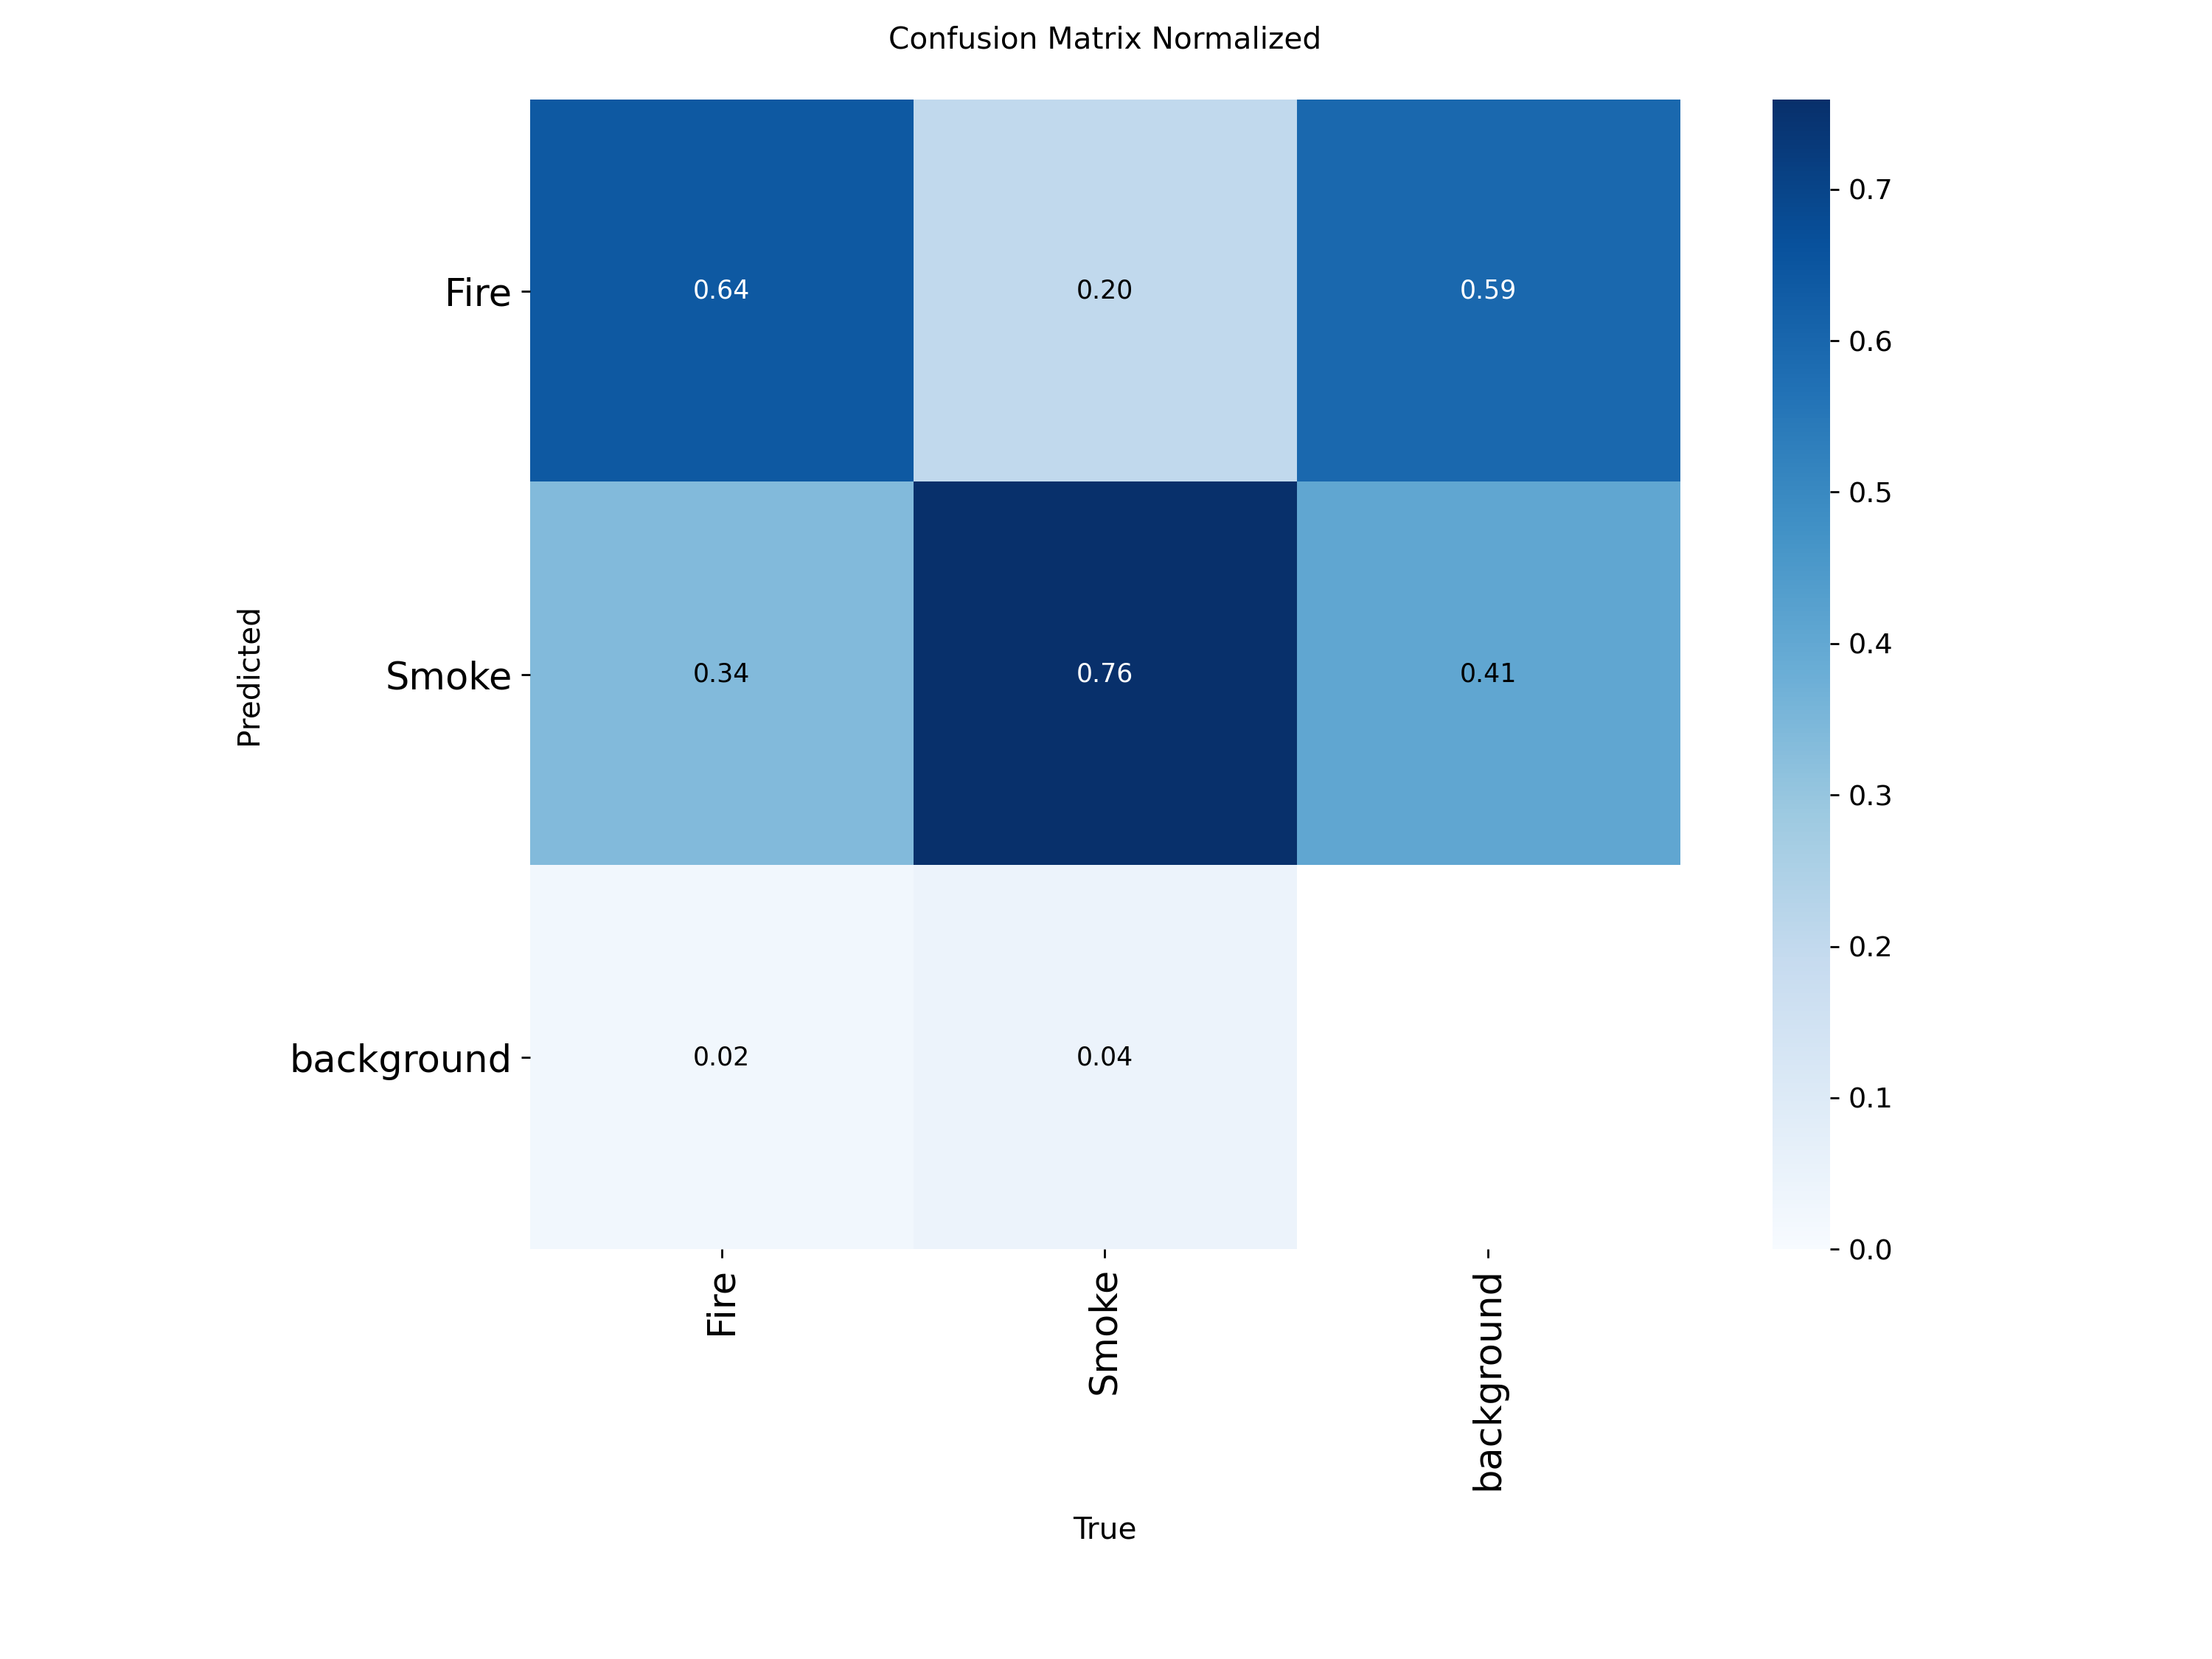

In [15]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path(
    "/kaggle/working/fire_smoke_yolo11/test_evaluation"
)

print("Available evaluation artifacts:")
for path in sorted(results_dir.iterdir()):
    print(path.name)

# Display common evaluation plots when available
plot_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]

for name in plot_names:
    path = results_dir / name
    if path.exists():
        print(f"\n{name}")
        display(Image(filename=str(path)))


0: 640x640 1 Fire, 4.8ms
1: 640x640 (no detections), 4.8ms
2: 640x640 1 Smoke, 4.8ms
3: 640x640 1 Fire, 4.8ms
4: 640x640 1 Fire, 4.8ms
5: 640x640 1 Fire, 4.8ms
6: 640x640 1 Fire, 4.8ms
7: 640x640 2 Fires, 4.8ms
8: 640x640 1 Fire, 4.8ms
9: 640x640 1 Fire, 4.8ms
10: 640x640 1 Fire, 1 Smoke, 4.8ms
11: 640x640 2 Fires, 4.8ms
Speed: 0.9ms preprocess, 4.8ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/fire_smoke_yolo11/test_prediction_examples
Prediction examples saved to: /kaggle/working/fire_smoke_yolo11/test_prediction_examples
-706551_png.rf.b039efbe7fabaf0d56bc6a5568eac63b.jpg


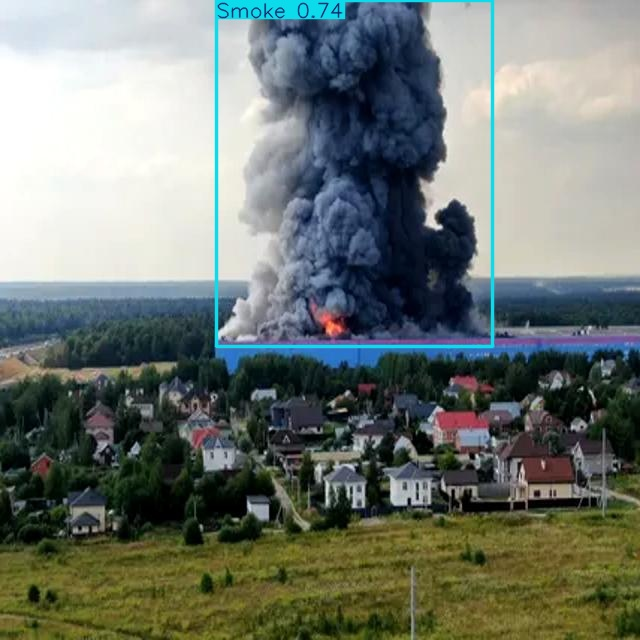

216_png_jpg.rf.a8096a0a55a1eeb4476cd8b6b89567d7.jpg


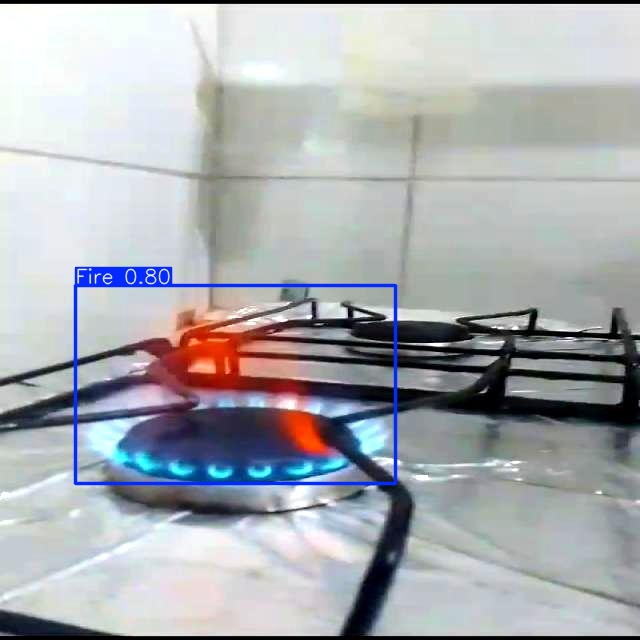

31587691_jpg.rf.a64f670762215a3febe77d87c0bcf545.jpg


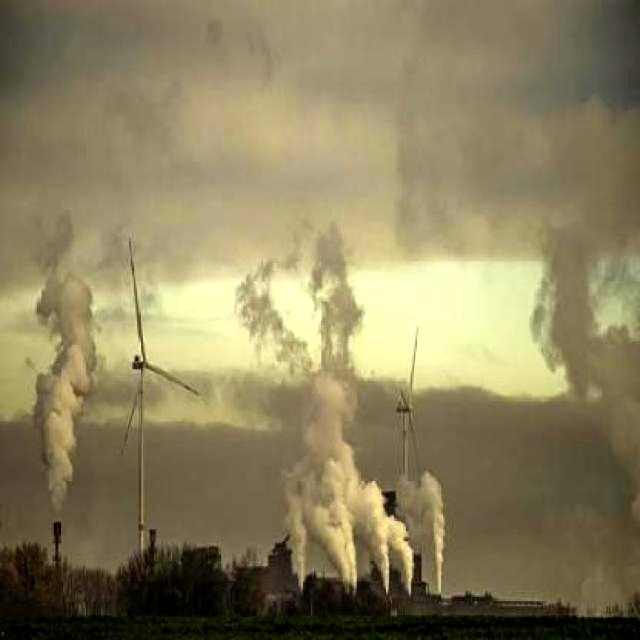

85df28e55d674dee_jpg.rf.0c59b91faa4b1d033117c504fcc6b64a.jpg


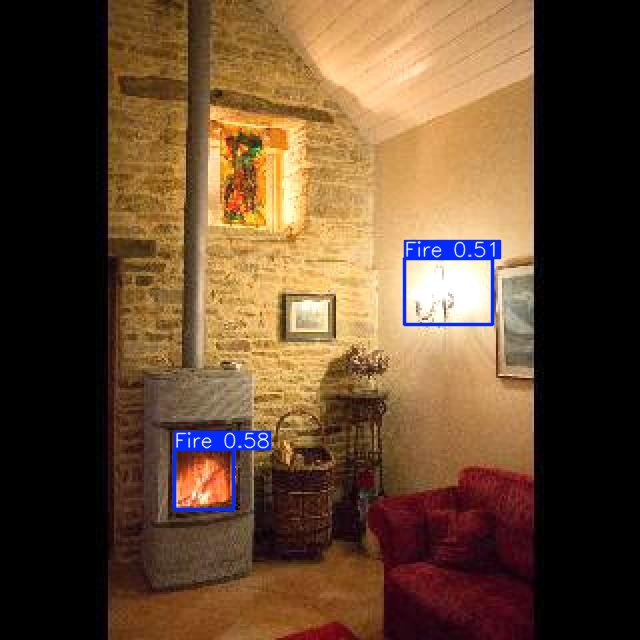

IMG_4007-1-_jpeg_jpg.rf.af34ea164a9ba9515cd9a75cdcc6f095.jpg


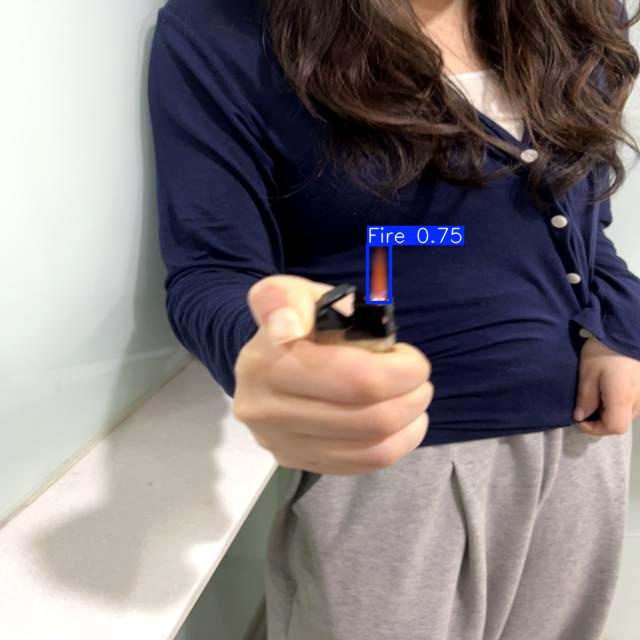

IMG_4224-1-_jpeg_jpg.rf.5beca1d636b9d6ffb933ce4132a78dc5.jpg


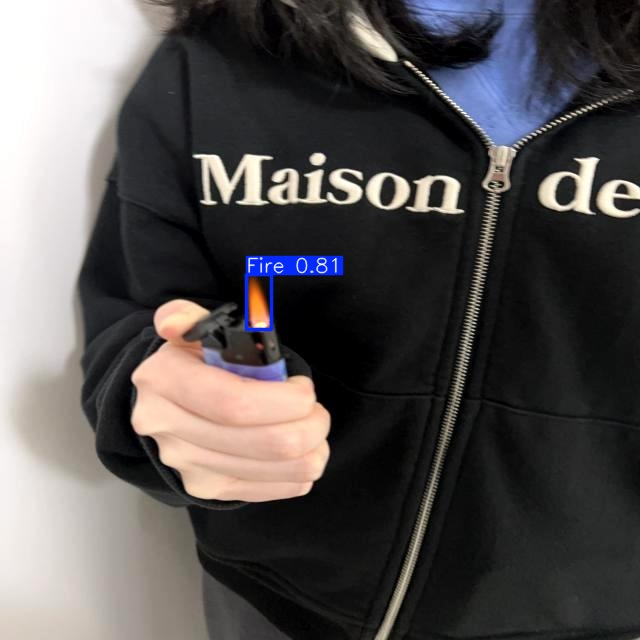

IMG_5737_jpeg_jpg.rf.761c345e2cf015c99a33e26ff5a53851.jpg


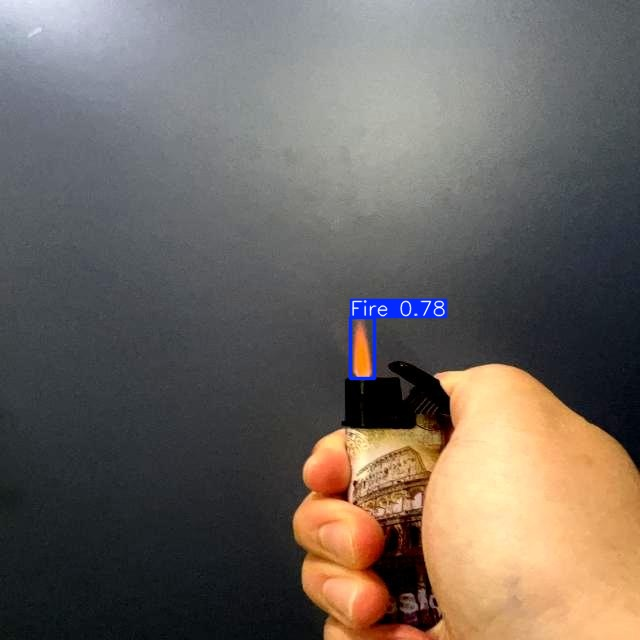

Img_348_jpg.rf.14742b48946fab2b1de9d7d8f16b44f9.jpg


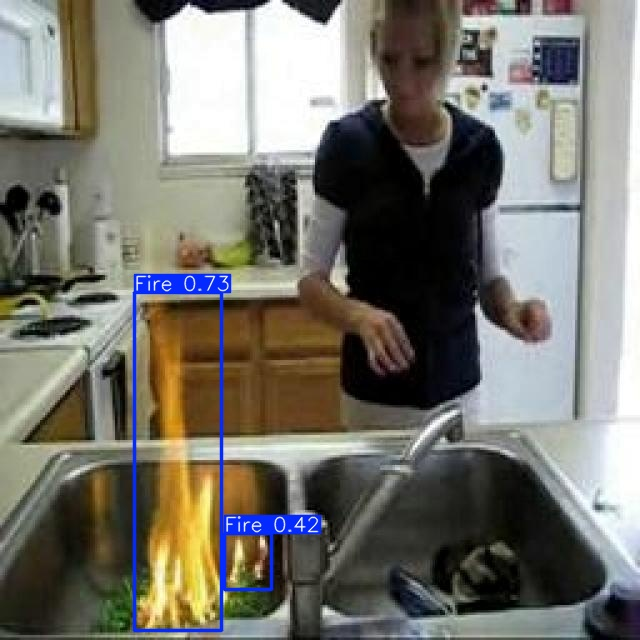

Img_86_jpg.rf.e65295d76a975ee55cd951b1ee19028a.jpg


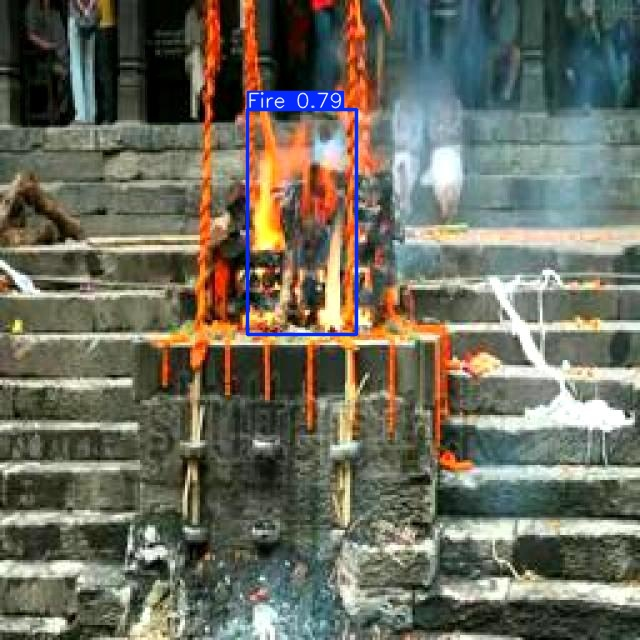

MirrorWEBSmoke2999_jpg.rf.d818c4f1edc124d28ad0739661a4fdb6.jpg


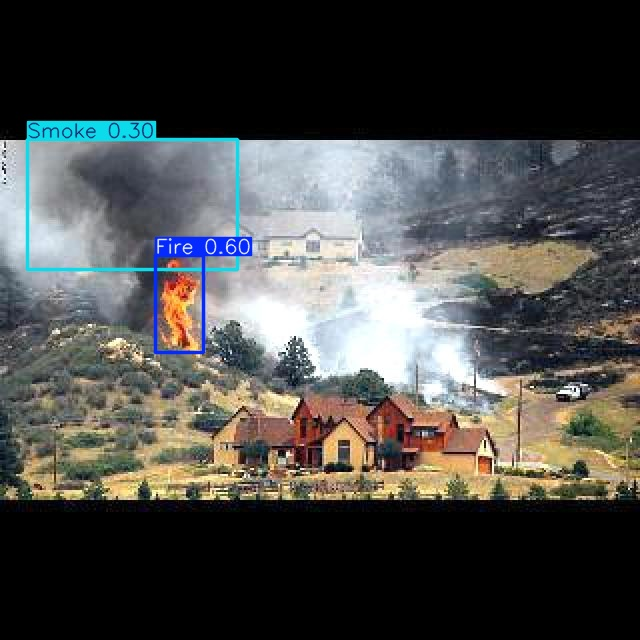

frame_046_jpg.rf.4efbfdf9787c46715c82eec6cad0838b.jpg


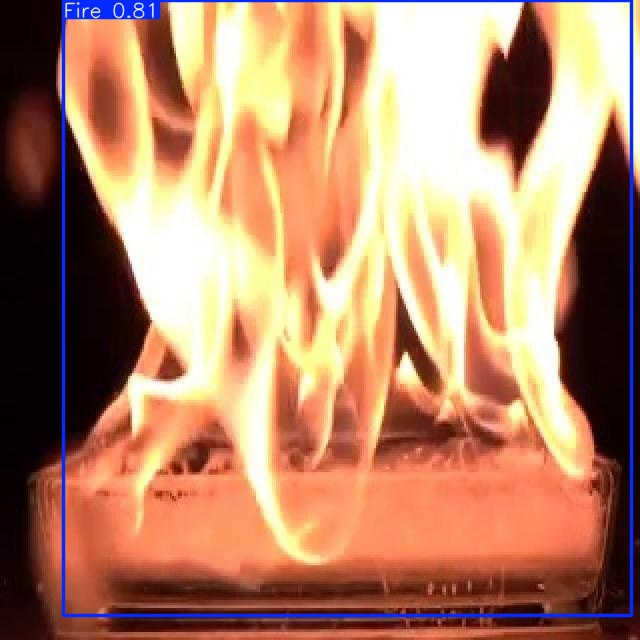

frame_051_jpg.rf.d1e949a209d313affed3b4aed980de0d.jpg


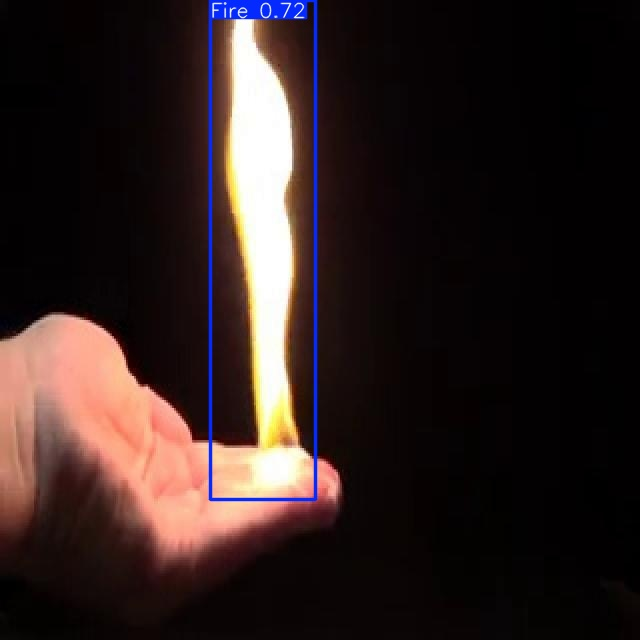

In [16]:
from pathlib import Path
from ultralytics import YOLO
from IPython.display import display, Image
import random

BEST_MODEL = (
    "/kaggle/working/fire_smoke_yolo11/"
    "yolo11n_fire_smoke/weights/best.pt"
)

TEST_IMAGES = Path(
    "/kaggle/working/Fire-Smoke-Detection-YOLO-detection/"
    "test/images"
)

OUTPUT_DIR = Path(
    "/kaggle/working/fire_smoke_yolo11/"
    "test_prediction_examples"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(42)
image_paths = sorted([
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
])

sample_paths = random.sample(image_paths, min(12, len(image_paths)))

model = YOLO(BEST_MODEL)

model.predict(
    source=[str(p) for p in sample_paths],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(OUTPUT_DIR.parent),
    name=OUTPUT_DIR.name,
    exist_ok=True
)

print("Prediction examples saved to:", OUTPUT_DIR)

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
        print(path.name)
        display(Image(filename=str(path)))

In [18]:
from pathlib import Path
import json
import shutil
import torch
import ultralytics

BASE_DIR = Path("/kaggle/working/fire_smoke_yolo11")
RUN_DIR = BASE_DIR / "yolo11n_fire_smoke"
TEST_DIR = BASE_DIR / "test_evaluation"

# Main artifacts
best_checkpoint = RUN_DIR / "weights" / "best.pt"
last_checkpoint = RUN_DIR / "weights" / "last.pt"
metrics_file = TEST_DIR / "test_metrics.json"

assert best_checkpoint.exists(), f"Missing checkpoint: {best_checkpoint}"
assert metrics_file.exists(), f"Missing test metrics: {metrics_file}"

test_metrics = json.loads(metrics_file.read_text())

experiment = {
    "experiment": "Terrestrial fire and smoke object detection",
    "model": "YOLO11n",
    "dataset": {
        "name": "Fire-Smoke-Detection-Yolov11",
        "version": 2,
        "source": (
            "https://universe.roboflow.com/"
            "sayed-gamal-kn2wu/fire-smoke-detection-yolov11/dataset/2"
        ),
        "license": "CC BY 4.0",
        "train_images": 9156,
        "validation_images": 872,
        "test_images": 435,
        "classes": ["Fire", "Smoke"],
        "preprocessing": (
            "Polygon segmentation annotations converted to enclosing "
            "axis-aligned bounding boxes; images retained unchanged."
        ),
    },
    "training": {
        "seed": 42,
        "image_size": 640,
        "batch_size": 16,
        "maximum_epochs": 50,
        "best_epoch": 40,
        "early_stopping_patience": 8,
        "optimizer": "AdamW",
        "initial_learning_rate": 0.001,
        "weight_decay": 0.0005,
        "pretrained": True,
        "hardware": "NVIDIA Tesla T4",
        "ultralytics_version": ultralytics.__version__,
        "torch_version": torch.__version__,
    },
    "test_metrics": test_metrics,
    "checkpoint_best": str(best_checkpoint),
    "checkpoint_last": str(last_checkpoint),
    "test_evaluation_directory": str(TEST_DIR),
}

record_path = BASE_DIR / "terrestrial_experiment_record.json"
record_path.write_text(json.dumps(experiment, indent=2))

# Keep a named copy of the selected checkpoint in the experiment folder.
archive_checkpoint = BASE_DIR / "terrestrial_yolo11n_best.pt"
if not archive_checkpoint.exists():
    shutil.copy2(best_checkpoint, archive_checkpoint)

print("Experiment record:", record_path)
print("Best checkpoint copy:", archive_checkpoint)
print(json.dumps(test_metrics, indent=2))

Experiment record: /kaggle/working/fire_smoke_yolo11/terrestrial_experiment_record.json
Best checkpoint copy: /kaggle/working/fire_smoke_yolo11/terrestrial_yolo11n_best.pt
{
  "precision": 0.765256545132499,
  "recall": 0.7021504639452079,
  "mAP50": 0.7591929424853421,
  "mAP50_95": 0.44552682027490886
}


In [21]:
from pathlib import Path

for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
    print(f"\nSearching {root}")
    for pattern in ["ts_satfire_unet_best (4).pt", "ts_satfire_split (4).json"]:
        matches = list(root.rglob(pattern))
        for path in matches[:10]:
            print(path)


Searching /kaggle/working

Searching /kaggle/input
/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_unet_best (4).pt
/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_split (4).json


In [22]:
from pathlib import Path
import json
import torch

CHECKPOINT = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_unet_best (4).pt"
)

SPLIT_FILE = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_split (4).json"
)

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"
assert SPLIT_FILE.exists(), f"Split file not found: {SPLIT_FILE}"

split = json.loads(SPLIT_FILE.read_text())

print("Checkpoint exists:", CHECKPOINT.exists())
print("Checkpoint size (MB):", round(CHECKPOINT.stat().st_size / 1e6, 2))
print("Split JSON top-level type:", type(split).__name__)
print("Split JSON keys:", list(split.keys()) if isinstance(split, dict) else "Not a dictionary")

print("\nSplit file preview:")
print(json.dumps(split, indent=2)[:4000])

checkpoint_data = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint_data).__name__)

if isinstance(checkpoint_data, dict):
    print("Checkpoint keys:", list(checkpoint_data.keys()))
    print("Saved epoch:", checkpoint_data.get("epoch"))
    print("Saved validation F1:", checkpoint_data.get("val_f1"))

Checkpoint exists: True
Checkpoint size (MB): 23.23
Split JSON top-level type: dict
Split JSON keys: ['seed', 'sequence_length', 'train_events', 'val_events', 'test_events']

Split file preview:
{
  "seed": 42,
  "sequence_length": 10,
  "train_events": [
    "20701026",
    "20702159",
    "20777181",
    "20777195",
    "20778153",
    "20778186",
    "20899673",
    "20899721",
    "20899766",
    "20899813",
    "20899892",
    "20899967",
    "20900085",
    "20900124",
    "20900131",
    "21158900",
    "21158940",
    "21748801",
    "21751303",
    "21751309",
    "21804985",
    "21889763",
    "21889943",
    "21890003",
    "21890009",
    "21890024",
    "21890072",
    "21890160",
    "21890524",
    "21997770",
    "21997828",
    "21998095",
    "21998264",
    "22141509",
    "22141596",
    "22343661",
    "22343688",
    "22938749",
    "23160475",
    "23300669",
    "23860939",
    "24103557",
    "24103571",
    "24103611",
    "24191347",
    "24191376",
    "241

In [23]:
from pathlib import Path
import torch
import json

CHECKPOINT = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_unet_best (4).pt"
)

SPLIT_FILE = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_split (4).json"
)

# 1. Find likely satellite dataset directories
print("Potential satellite data directories:\n")

for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
    for p in root.iterdir():
        print(p)

print("\nSearch for GeoTIFF files (first 30 matches):")
count = 0
for root in Path("/kaggle/input").rglob("*"):
    if root.is_file() and root.suffix.lower() in {".tif", ".tiff"}:
        print(root)
        count += 1
        if count >= 30:
            break

# 2. Inspect saved model parameter names and shapes
checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model_state_dict"]

print("\nCheckpoint epoch:", checkpoint["epoch"])
print("Validation F1:", checkpoint["val_f1"])
print("Number of state-dict entries:", len(state))
print("\nFirst 40 model parameters:")

for i, (name, tensor) in enumerate(state.items()):
    print(name, tuple(tensor.shape))
    if i >= 39:
        break

# 3. Confirm test split size
split = json.loads(SPLIT_FILE.read_text())
print("\nTrain events:", len(split["train_events"]))
print("Validation events:", len(split["val_events"]))
print("Test events:", len(split["test_events"]))
print("Sequence length:", split["sequence_length"])

Potential satellite data directories:

/kaggle/input/datasets
/kaggle/working/Fire-Smoke-Detection-YOLO-detection
/kaggle/working/Fire-Smoke-Detection-Yolov11-2
/kaggle/working/fire_smoke_yolo11
/kaggle/working/weights
/kaggle/working/.virtual_documents
/kaggle/working/yolo11n.pt

Search for GeoTIFF files (first 30 matches):

Checkpoint epoch: 4
Validation F1: 0.7873871369670997
Number of state-dict entries: 92

First 40 model parameters:
unet.enc1.block.0.weight (32, 8, 3, 3)
unet.enc1.block.1.weight (32,)
unet.enc1.block.1.bias (32,)
unet.enc1.block.1.running_mean (32,)
unet.enc1.block.1.running_var (32,)
unet.enc1.block.1.num_batches_tracked ()
unet.enc1.block.3.weight (32, 32, 3, 3)
unet.enc1.block.4.weight (32,)
unet.enc1.block.4.bias (32,)
unet.enc1.block.4.running_mean (32,)
unet.enc1.block.4.running_var (32,)
unet.enc1.block.4.num_batches_tracked ()
unet.enc2.block.0.weight (64, 32, 3, 3)
unet.enc2.block.1.weight (64,)
unet.enc2.block.1.bias (64,)
unet.enc2.block.1.running_mean

In [24]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

tif_count = 0
event_dirs = set()

for tif in INPUT_DIR.rglob("*.tif"):
    tif_count += 1
    # Event folder is expected to contain the GeoTIFF
    # or its immediate parent folders.
    event_dirs.add(tif.parent.name)

for tif in INPUT_DIR.rglob("*.tiff"):
    tif_count += 1
    event_dirs.add(tif.parent.name)

print("GeoTIFF files found:", tif_count)
print("Example folders:")
for name in sorted(event_dirs)[:30]:
    print(" ", name)

GeoTIFF files found: 0
Example folders:


In [25]:
from pathlib import Path
import zipfile

BASE = Path("/kaggle/working/fire_smoke_yolo11")
BACKUP = Path("/kaggle/working/terrestrial_yolo11_experiment_backup.zip")

# Include the complete training and evaluation directories,
# experiment record, and a separate copy of the best checkpoint.
include_paths = [
    BASE / "yolo11n_fire_smoke",
    BASE / "test_evaluation",
    BASE / "test_prediction_examples",
    BASE / "terrestrial_experiment_record.json",
    BASE / "terrestrial_yolo11n_best.pt",
]

with zipfile.ZipFile(
    BACKUP, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in include_paths:
        if not path.exists():
            print("Not found, skipping:", path)
            continue

        if path.is_file():
            zf.write(path, path.relative_to(BASE))
        else:
            for file in path.rglob("*"):
                if file.is_file():
                    zf.write(file, file.relative_to(BASE))

print("Backup created:", BACKUP)
print("ZIP size (MB):", round(BACKUP.stat().st_size / 1e6, 2))

Backup created: /kaggle/working/terrestrial_yolo11_experiment_backup.zip
ZIP size (MB): 26.8


In [26]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/terrestrial_yolo11_experiment_backup.zip"
))

/kaggle/working/terrestrial_yolo11_experiment_backup.zip

In [1]:
from pathlib import Path

INPUT = Path("/kaggle/input")

print("Checking Kaggle inputs...\n")

for item in INPUT.iterdir():
    print(f"📁 {item}")

# Search for TS-SatFire folders and GeoTIFF files
sat_folders = [
    p for p in INPUT.rglob("*")
    if p.is_dir() and "ts-satfire" in p.name.lower()
]

tif_files = list(INPUT.rglob("*.tif")) + list(INPUT.rglob("*.tiff"))

print("\n" + "=" * 45)

if sat_folders:
    print("✅ Possible TS-SatFire folders found:")
    for folder in sat_folders[:10]:
        print(folder)
elif tif_files:
    print("✅ GeoTIFF files found — TS-SatFire data may be attached.")
else:
    print("❌ No TS-SatFire folders or GeoTIFF files found.")

print(f"\nTotal GeoTIFF files found: {len(tif_files)}")

Checking Kaggle inputs...

📁 /kaggle/input/datasets

✅ Possible TS-SatFire folders found:
/kaggle/input/datasets/z789456sx/ts-satfire
/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire

Total GeoTIFF files found: 10811


In [2]:
from pathlib import Path
import json
import torch

# Saved files attached to this notebook
checkpoint_path = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_unet_best (4).pt"
)
split_path = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_split (4).json"
)

print("Checkpoint exists:", checkpoint_path.exists())
print("Split JSON exists:", split_path.exists())

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    print("Best epoch:", checkpoint.get("epoch"))
    print("Best validation F1:", checkpoint.get("val_f1"))
    print("Model state entries:", len(checkpoint["model_state_dict"]))

if split_path.exists():
    with open(split_path, "r") as f:
        split = json.load(f)

    print("Sequence length:", split["sequence_length"])
    print("Train events:", len(split["train_events"]))
    print("Validation events:", len(split["val_events"]))
    print("Test events:", len(split["test_events"]))

Checkpoint exists: True
Split JSON exists: True
Best epoch: 4
Best validation F1: 0.7873871369670997
Model state entries: 92
Sequence length: 10
Train events: 101
Validation events: 21
Test events: 24


In [3]:
from pathlib import Path

DATA_ROOT = Path("/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire")

print("Dataset root exists:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    event_dirs = sorted(p for p in DATA_ROOT.iterdir() if p.is_dir())
    print("Event folders:", len(event_dirs))

    for event_dir in event_dirs[:5]:
        print(f"\nEvent: {event_dir.name}")
        for subfolder in ["VIIRS_Day", "VIIRS_Night", "FirePred", "ESRI_LULC"]:
            folder = event_dir / subfolder
            if folder.exists():
                files = sorted(
                    p for p in folder.iterdir()
                    if p.suffix.lower() in [".tif", ".tiff"]
                )
                print(f"  {subfolder}: {len(files)} TIFF files")
                if files:
                    print("    Example:", files[0].name)
            else:
                print(f"  {subfolder}: not found")

Dataset root exists: True
Event folders: 192

Event: 20562846
  VIIRS_Day: 8 TIFF files
    Example: 2017-04-23_VIIRS_Day.tif
  VIIRS_Night: 8 TIFF files
    Example: 2017-04-23_VIIRS_Night.tif
  FirePred: 8 TIFF files
    Example: 2017-04-23_FirePred.tif
  ESRI_LULC: 1 TIFF files
    Example: 2017-01-01_ESRI_LULC.tif

Event: 20568194
  VIIRS_Day: 38 TIFF files
    Example: 2017-04-08_VIIRS_Day.tif
  VIIRS_Night: 38 TIFF files
    Example: 2017-04-08_VIIRS_Night.tif
  FirePred: 38 TIFF files
    Example: 2017-04-08_FirePred.tif
  ESRI_LULC: 1 TIFF files
    Example: 2017-01-01_ESRI_LULC.tif

Event: 20700973
  VIIRS_Day: 9 TIFF files
    Example: 2017-06-22_VIIRS_Day.tif
  VIIRS_Night: 9 TIFF files
    Example: 2017-06-22_VIIRS_Night.tif
  FirePred: 9 TIFF files
    Example: 2017-06-22_FirePred.tif
  ESRI_LULC: 1 TIFF files
    Example: 2017-01-01_ESRI_LULC.tif

Event: 20701026
  VIIRS_Day: 24 TIFF files
    Example: 2017-06-08_VIIRS_Day.tif
  VIIRS_Night: 24 TIFF files
    Example: 201

In [4]:
from pathlib import Path
import json

DATA_ROOT = Path("/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire")
SPLIT_PATH = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_split (4).json"
)

with open(SPLIT_PATH, "r") as f:
    split = json.load(f)

test_events = split["test_events"]
SEQ_LEN = split["sequence_length"]

print("Test events in saved split:", len(test_events))
print("Required sequence length:", SEQ_LEN)

missing_events = []
short_events = []
valid_events = []

for event_id in test_events:
    event_dir = DATA_ROOT / str(event_id)

    if not event_dir.is_dir():
        missing_events.append(str(event_id))
        print(f"MISSING EVENT: {event_id}")
        continue

    day_dir = event_dir / "VIIRS_Day"
    night_dir = event_dir / "VIIRS_Night"

    day_files = {
        p.stem.replace("_VIIRS_Day", ""): p
        for p in day_dir.glob("*.tif")
    } if day_dir.exists() else {}

    night_files = {
        p.stem.replace("_VIIRS_Night", ""): p
        for p in night_dir.glob("*.tif")
    } if night_dir.exists() else {}

    matching_dates = sorted(set(day_files) & set(night_files))
    window_count = max(0, len(matching_dates) - SEQ_LEN + 1)

    if len(matching_dates) < SEQ_LEN:
        short_events.append((str(event_id), len(matching_dates)))
    else:
        valid_events.append((str(event_id), len(matching_dates), window_count))

print("\n--- Validation summary ---")
print("Missing events:", len(missing_events))
print("Events with fewer than 10 matching observations:", len(short_events))
print("Events with enough observations:", len(valid_events))
print("Potential test windows:", sum(x[2] for x in valid_events))

if short_events:
    print("\nShort events:", short_events)

if missing_events:
    print("\nMissing event IDs:", missing_events)

Test events in saved split: 24
Required sequence length: 10

--- Validation summary ---
Missing events: 0
Events with fewer than 10 matching observations: 0
Events with enough observations: 24
Potential test windows: 370


In [5]:
from pathlib import Path
import numpy as np
import rasterio
import json

DATA_ROOT = Path("/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire")
SPLIT_PATH = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_split (4).json"
)

with open(SPLIT_PATH, "r") as f:
    split = json.load(f)

event_id = split["test_events"][0]
event_dir = DATA_ROOT / str(event_id)

day_file = sorted((event_dir / "VIIRS_Day").glob("*.tif"))[0]
night_file = sorted((event_dir / "VIIRS_Night").glob("*.tif"))[0]

with rasterio.open(day_file) as src:
    day = src.read()
    print("Event:", event_id)
    print("Day file:", day_file.name)
    print("Day shape (bands, height, width):", day.shape)
    print("Day band descriptions:", src.descriptions)
    print("Day dtype:", day.dtype)

    if day.shape[0] >= 7:
        af = day[6]
        mask = np.isfinite(af) & (af > 0)
        print("Active-fire band min/max:", np.nanmin(af), np.nanmax(af))
        print("Positive fire pixels:", int(mask.sum()))
        print("Total pixels:", int(mask.size))
        print("Fire pixel fraction:", float(mask.mean()))

with rasterio.open(night_file) as src:
    night = src.read()
    print("\nNight file:", night_file.name)
    print("Night shape (bands, height, width):", night.shape)
    print("Night band descriptions:", src.descriptions)

print("\nExpected model channels: 8 (6 Day + 2 Night)")
print("Expected crop: 256 x 256")

Event: 20568194
Day file: 2017-04-08_VIIRS_Day.tif
Day shape (bands, height, width): (8, 596, 594)
Day band descriptions: ('b1', 'b2', 'b3', 'b4', 'b5', 'm11', 'af', 'first')
Day dtype: float32
Active-fire band min/max: 279.08 313.91
Positive fire pixels: 67
Total pixels: 354024
Fire pixel fraction: 0.00018925270603122952

Night file: 2017-04-08_VIIRS_Night.tif
Night shape (bands, height, width): (2, 596, 594)
Night band descriptions: ('b1', 'b2')

Expected model channels: 8 (6 Day + 2 Night)
Expected crop: 256 x 256


In [7]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_unet_best (4).pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model_state_dict"]

print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation F1:", checkpoint["val_f1"])
print("\n--- Saved model layer names and parameter shapes ---")

for name, tensor in state.items():
    print(f"{name:45s} {tuple(tensor.shape)}")

Checkpoint epoch: 4
Validation F1: 0.7873871369670997

--- Saved model layer names and parameter shapes ---
unet.enc1.block.0.weight                      (32, 8, 3, 3)
unet.enc1.block.1.weight                      (32,)
unet.enc1.block.1.bias                        (32,)
unet.enc1.block.1.running_mean                (32,)
unet.enc1.block.1.running_var                 (32,)
unet.enc1.block.1.num_batches_tracked         ()
unet.enc1.block.3.weight                      (32, 32, 3, 3)
unet.enc1.block.4.weight                      (32,)
unet.enc1.block.4.bias                        (32,)
unet.enc1.block.4.running_mean                (32,)
unet.enc1.block.4.running_var                 (32,)
unet.enc1.block.4.num_batches_tracked         ()
unet.enc2.block.0.weight                      (64, 32, 3, 3)
unet.enc2.block.1.weight                      (64,)
unet.enc2.block.1.bias                        (64,)
unet.enc2.block.1.running_mean                (64,)
unet.enc2.block.1.running_var           

In [8]:
import torch
import torch.nn as nn
from pathlib import Path

CHECKPOINT_PATH = Path(
    "/kaggle/input/datasets/akaashmahe4/tssatss/ts_satfire_unet_best (4).pt"
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=8, out_ch=1):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_ch, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


class TemporalUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.unet = UNet(in_ch=8, out_ch=1)

    def forward(self, x):
        # x shape: [batch, time, channels, height, width]
        b, t, c, h, w = x.shape
        x = x.reshape(b * t, c, h, w)
        y = self.unet(x)
        return y.reshape(b, t, 1, h, w).squeeze(2)


checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model = TemporalUNet().to(DEVICE)

# Strict loading: every expected parameter must match.
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

print("✅ Checkpoint loaded successfully!")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved validation F1:", checkpoint["val_f1"])
print("Device:", DEVICE)

# Confirm the model's output dimensions with a dummy input.
with torch.inference_mode():
    dummy = torch.zeros(1, 10, 8, 256, 256, device=DEVICE)
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

✅ Checkpoint loaded successfully!
Checkpoint epoch: 4
Saved validation F1: 0.7873871369670997
Device: cuda
Input shape: (1, 10, 8, 256, 256)
Output shape: (1, 10, 256, 256)


In [11]:
import os
import json
import re
import glob
import random
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn as nn
from tqdm.auto import tqdm

SEED = 42
SEQ_LEN = 10
CROP_START = 128
CROP_SIZE = 256
BATCH_SIZE = 1
THRESHOLD = 0.5

DATA_ROOT = "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
CHECKPOINT_PATH = (
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_unet_best (4).pt"
)
SPLIT_PATH = (
    "/kaggle/input/datasets/akaashmahe4/tssatss/"
    "ts_satfire_split (4).json"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Dataset exists:", os.path.isdir(DATA_ROOT))
print("Checkpoint exists:", os.path.isfile(CHECKPOINT_PATH))
print("Split file exists:", os.path.isfile(SPLIT_PATH))

assert os.path.isdir(DATA_ROOT), f"Dataset not found: {DATA_ROOT}"
assert os.path.isfile(CHECKPOINT_PATH), "Checkpoint file not found"
assert os.path.isfile(SPLIT_PATH), "Split JSON file not found"
with open(SPLIT_PATH, "r") as f:
    split = json.load(f)

test_events = [str(x) for x in split["test_events"]]

print("Split seed:", split.get("seed"))
print("Sequence length in split:", split.get("sequence_length"))
print("Train events:", len(split["train_events"]))
print("Validation events:", len(split["val_events"]))
print("Test events:", len(test_events))
print("\nTest events:")
print(test_events)

assert len(test_events) > 0
assert not set(test_events) & set(split["train_events"])
assert not set(test_events) & set(split["val_events"])
event_dirs = {}

for name in os.listdir(DATA_ROOT):
    path = os.path.join(DATA_ROOT, name)
    if os.path.isdir(path):
        event_dirs[str(name)] = path

missing_events = [e for e in test_events if e not in event_dirs]

print("Event folders found:", len(event_dirs))
print("Test events missing from dataset:", len(missing_events))

if missing_events:
    print(missing_events)

assert not missing_events, (
    "Some test event folders are missing. Check DATA_ROOT and the split file."
)
sample_event = test_events[0]
sample_dir = event_dirs[sample_event]

sample_day_files = sorted(
    glob.glob(os.path.join(sample_dir, "**", "*VIIRS_Day.tif"), recursive=True)
)

assert sample_day_files, f"No VIIRS_Day TIFF found for {sample_event}"

with rasterio.open(sample_day_files[0]) as src:
    print("Sample file:", sample_day_files[0])
    print("Raster shape:", src.count, src.height, src.width)
    print("Band descriptions:", src.descriptions)

    if src.count < 7:
        raise ValueError("Expected at least 7 Day bands, including the af band.")

    af = src.read(7).astype(np.float32)
    finite = np.isfinite(af)
    positive = finite & (af > 0)

    print("Finite af pixels:", int(finite.sum()))
    print("Positive finite af pixels:", int(positive.sum()))
    print("Positive fraction across raster:", float(positive.mean()))

    if finite.any():
        print("Finite af min:", float(np.nanmin(af)))
        print("Finite af max:", float(np.nanmax(af)))

if positive.sum() == 0:
    raise ValueError(
        "Sample target mask is empty. Verify the dataset's official label definition."
    )
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=8, out_ch=1):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_ch, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_ch, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final(d1)


class TemporalUNet(nn.Module):
    """
    Applies the same 2D U-Net independently to every frame.
    Input:  [B, T, 8, H, W]
    Output: [B, T, H, W]
    """
    def __init__(self):
        super().__init__()
        self.unet = UNet(in_ch=8, out_ch=1)

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.reshape(b * t, c, h, w)
        y = self.unet(x)
        return y.reshape(b, t, 1, h, w).squeeze(2)


model = TemporalUNet().to(device)

print("Model parameters:", sum(p.numel() for p in model.parameters()))
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint validation F1:", checkpoint.get("val_f1"))

state_dict = checkpoint.get("model_state_dict")
assert state_dict is not None, "Checkpoint has no model_state_dict"

# Strict loading verifies that the architecture matches the saved weights.
model.load_state_dict(state_dict, strict=True)
model.eval()

print("Checkpoint loaded successfully.")
CHANNEL_MEAN = np.array([
    18.76488, 27.441864, 20.584806, 305.99478,
    294.31738, 14.625097, 276.4207, 275.16766
], dtype=np.float32)

CHANNEL_STD = np.array([
    15.911591, 14.879259, 10.832616, 21.761852,
    24.703484, 9.878246, 40.64329, 40.7657
], dtype=np.float32)

assert len(CHANNEL_MEAN) == 8
assert len(CHANNEL_STD) == 8
assert np.all(CHANNEL_STD > 0)

print("Eight-channel normalization configured.")
def get_date_key(path, suffix):
    name = os.path.basename(path)
    if suffix not in name:
        return None
    return name.split(suffix)[0].rstrip("_")


def find_day_night_pairs(event_dir):
    day_files = glob.glob(
        os.path.join(event_dir, "**", "*VIIRS_Day.tif"),
        recursive=True
    )
    night_files = glob.glob(
        os.path.join(event_dir, "**", "*VIIRS_Night.tif"),
        recursive=True
    )

    day_by_date = {}
    night_by_date = {}

    for path in day_files:
        key = get_date_key(path, "VIIRS_Day.tif")
        if key is not None:
            day_by_date[key] = path

    for path in night_files:
        key = get_date_key(path, "VIIRS_Night.tif")
        if key is not None:
            night_by_date[key] = path

    common_dates = sorted(set(day_by_date) & set(night_by_date))

    return [
        (date, day_by_date[date], night_by_date[date])
        for date in common_dates
    ]


for event in test_events[:3]:
    pairs = find_day_night_pairs(event_dirs[event])
    print(event, "matched observations:", len(pairs))
def read_observation(day_path, night_path):
    with rasterio.open(day_path) as src:
        day = src.read().astype(np.float32)

    with rasterio.open(night_path) as src:
        night = src.read().astype(np.float32)

    if day.shape[0] < 7:
        raise ValueError(f"Day file has fewer than 7 bands: {day_path}")
    if night.shape[0] < 2:
        raise ValueError(f"Night file has fewer than 2 bands: {night_path}")

    y0 = CROP_START
    x0 = CROP_START
    y1 = y0 + CROP_SIZE
    x1 = x0 + CROP_SIZE

    day_input = day[:6, y0:y1, x0:x1]
    night_input = night[:2, y0:y1, x0:x1]
    active_fire = day[6, y0:y1, x0:x1]

    if day_input.shape != (6, CROP_SIZE, CROP_SIZE):
        raise ValueError(f"Unexpected Day crop shape: {day_input.shape}")
    if night_input.shape != (2, CROP_SIZE, CROP_SIZE):
        raise ValueError(f"Unexpected Night crop shape: {night_input.shape}")

    X = np.concatenate([day_input, night_input], axis=0)

    # Match training: clean input before normalization.
    X = np.nan_to_num(
        X, nan=0.0, posinf=0.0, neginf=0.0
    )

    X = (
        X - CHANNEL_MEAN[:, None, None]
    ) / (
        CHANNEL_STD[:, None, None] + 1e-8
    )

    Y = (
        np.isfinite(active_fire) & (active_fire > 0)
    ).astype(np.uint8)

    return X.astype(np.float32), Y
test_sequences = []
skipped_events = []

for event in tqdm(test_events, desc="Preparing test events"):
    pairs = find_day_night_pairs(event_dirs[event])

    if len(pairs) < SEQ_LEN:
        skipped_events.append((event, len(pairs)))
        continue

    # Sliding windows of length 10, matching the saved split's sequence length.
    for start in range(len(pairs) - SEQ_LEN + 1):
        window = pairs[start:start + SEQ_LEN]

        test_sequences.append({
            "event": event,
            "dates": [item[0] for item in window],
            "pairs": window
        })

print("Test sequences prepared:", len(test_sequences))
print("Events with too few observations:", skipped_events)

assert test_sequences, "No test sequences were generated."
tp = 0
fp = 0
fn = 0
tn = 0

per_event_counts = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0, "tn": 0})
bad_windows = []

with torch.no_grad():
    for sequence in tqdm(test_sequences, desc="Evaluating test sequences"):
        xs = []
        ys = []

        try:
            for _, day_path, night_path in sequence["pairs"]:
                x, y = read_observation(day_path, night_path)
                xs.append(x)
                ys.append(y)

            # [T, C, H, W] -> [1, T, C, H, W]
            x_tensor = torch.from_numpy(np.stack(xs)).unsqueeze(0).to(device)
            y_true = np.stack(ys).astype(bool)

            logits = model(x_tensor)
            probabilities = torch.sigmoid(logits).cpu().numpy()[0]
            y_pred = probabilities >= THRESHOLD

            if y_pred.shape != y_true.shape:
                raise ValueError(
                    f"Prediction shape {y_pred.shape} != target shape {y_true.shape}"
                )

            event = sequence["event"]

            etp = int(np.logical_and(y_pred, y_true).sum())
            efp = int(np.logical_and(y_pred, ~y_true).sum())
            efn = int(np.logical_and(~y_pred, y_true).sum())
            etn = int(np.logical_and(~y_pred, ~y_true).sum())

            tp += etp
            fp += efp
            fn += efn
            tn += etn

            per_event_counts[event]["tp"] += etp
            per_event_counts[event]["fp"] += efp
            per_event_counts[event]["fn"] += efn
            per_event_counts[event]["tn"] += etn

        except Exception as exc:
            bad_windows.append({
                "event": sequence["event"],
                "dates": sequence["dates"],
                "error": repr(exc)
            })

print("Evaluation loop finished.")
print("Failed windows:", len(bad_windows))

if bad_windows:
    print("First failures:")
    for item in bad_windows[:5]:
        print(item)
def calculate_metrics(tp, fp, fn, tn):
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0.0
    )
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0
    accuracy = (tp + tn) / (tp + fp + fn + tn) if (tp + fp + fn + tn) else 0.0

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou,
        "Accuracy": accuracy
    }


overall_metrics = calculate_metrics(tp, fp, fn, tn)

print("\nOVERALL TEST METRICS")
print("=" * 45)
for key, value in overall_metrics.items():
    if isinstance(value, float):
        print(f"{key:12s}: {value:.6f}")
    else:
        print(f"{key:12s}: {value:,}")
event_rows = []

for event, counts in sorted(per_event_counts.items()):
    metrics = calculate_metrics(
        counts["tp"], counts["fp"], counts["fn"], counts["tn"]
    )
    metrics["Event"] = event
    event_rows.append(metrics)

event_df = pd.DataFrame(event_rows)

if not event_df.empty:
    event_df = event_df[
        ["Event", "TP", "FP", "FN", "TN",
         "Precision", "Recall", "F1", "IoU", "Accuracy"]
    ]

display(event_df)

overall_df = pd.DataFrame([overall_metrics])
overall_df.to_csv("/kaggle/working/ts_satfire_test_overall.csv", index=False)
event_df.to_csv("/kaggle/working/ts_satfire_test_per_event.csv", index=False)

with open("/kaggle/working/ts_satfire_test_failures.json", "w") as f:
    json.dump(bad_windows, f, indent=2)

print("Saved:")
print("/kaggle/working/ts_satfire_test_overall.csv")
print("/kaggle/working/ts_satfire_test_per_event.csv")
print("/kaggle/working/ts_satfire_test_failures.json")

Device: cuda
Dataset exists: True
Checkpoint exists: True
Split file exists: True
Split seed: 42
Sequence length in split: 10
Train events: 101
Validation events: 21
Test events: 24

Test events:
['20568194', '20777134', '21038333', '21158939', '21693566', '21804884', '21890502', '21998313', '21999381', '22712904', '22712973', '24332608', '24332760', '24332939', '24332956', '24333270', '24462753', '24462788', 'US_2021_MT4568311385420210708', 'US_2021_NM3344410803520210514', 'US_2021_WA4879111827120210805', 'calfcanyon_fire', 'lytton_fire', 'mosquito_fire']
Event folders found: 192
Test events missing from dataset: 0
Sample file: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/20568194/VIIRS_Day/2017-04-08_VIIRS_Day.tif
Raster shape: 8 596 594
Band descriptions: ('b1', 'b2', 'b3', 'b4', 'b5', 'm11', 'af', 'first')
Finite af pixels: 67
Positive finite af pixels: 67
Positive fraction across raster: 0.00018925270603122952
Finite af min: 279.0799865722656
Finite af max: 313.910003662

Preparing test events:   0%|          | 0/24 [00:00<?, ?it/s]

Test sequences prepared: 370
Events with too few observations: []


Evaluating test sequences:   0%|          | 0/370 [00:00<?, ?it/s]

Evaluation loop finished.
Failed windows: 0

OVERALL TEST METRICS
TP          : 726,763
FP          : 117,643
FN          : 344,684
TN          : 241,294,110
Precision   : 0.860680
Recall      : 0.678300
F1          : 0.758683
IoU         : 0.611193
Accuracy    : 0.998093


,Event,TP,FP,FN,TN,Precision,Recall,F1,IoU,Accuracy
0,20568194,18557,3076,23570,18960237,0.857810,0.440501,0.582089,0.410526,0.998598
1,20777134,105690,21620,35307,27362503,0.830178,0.749590,0.787829,0.649932,0.997932
2,21038333,4423,1266,3450,3267661,0.777465,0.561793,0.652264,0.483970,0.998561
3,21158939,36747,6250,9335,4535188,0.854641,0.797426,0.825043,0.702190,0.996603
4,21693566,0,1453,0,7207507,0.000000,0.000000,0.000000,0.000000,0.999798
5,21804884,452,21,1768,653119,0.955603,0.203604,0.335685,0.201696,0.997270
6,21890502,61660,9970,51738,22158872,0.860813,0.543749,0.666494,0.499805,0.997231
7,21998313,11943,1072,10635,9806750,0.917633,0.528966,0.671087,0.504989,0.998809
8,21999381,7289,831,2879,5887241,0.897660,0.716857,0.797135,0.662697,0.999371
9,22712904,0,4557,0,4582963,0.000000,0.000000,0.000000,0.000000,0.999007


Saved:
/kaggle/working/ts_satfire_test_overall.csv
/kaggle/working/ts_satfire_test_per_event.csv
/kaggle/working/ts_satfire_test_failures.json


In [6]:
import os
import re
import json
import csv
import time
import random
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import rasterio

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
TS_ROOT = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

print("TS-SatFire root:")
print(TS_ROOT)

print("\nExists:", TS_ROOT.exists())
day_files = list(
    TS_ROOT.rglob("*_VIIRS_Day.tif")
)

night_files = list(
    TS_ROOT.rglob("*_VIIRS_Night.tif")
)

print("Day files   :", len(day_files))
print("Night files :", len(night_files))


date_pattern = re.compile(
    r"(\d{4}-\d{2}-\d{2})"
)


day_index = defaultdict(dict)
night_index = defaultdict(dict)


for path in day_files:

    event_id = path.parent.parent.name

    match = date_pattern.search(path.name)

    if match:
        date = match.group(1)
        day_index[event_id][date] = path


for path in night_files:

    event_id = path.parent.parent.name

    match = date_pattern.search(path.name)

    if match:
        date = match.group(1)
        night_index[event_id][date] = path


events = {}

for event_id in sorted(day_index.keys()):

    common_dates = sorted(
        set(day_index[event_id]) &
        set(night_index[event_id])
    )

    if common_dates:
        events[event_id] = common_dates


SEQUENCE_LENGTH = 10


eligible_events = {
    event_id: dates
    for event_id, dates in events.items()
    if len(dates) >= SEQUENCE_LENGTH
}


print("\n========== DATASET INDEX ==========")

print("Total events found      :", len(events))

print(
    "Eligible events (>=10) :",
    len(eligible_events)
)

total_observations = sum(
    len(dates)
    for dates in eligible_events.values()
)

total_windows = sum(
    len(dates) - SEQUENCE_LENGTH + 1
    for dates in eligible_events.values()
)

print(
    "Usable observations     :",
    total_observations
)

print(
    "10-frame windows        :",
    total_windows
)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
TS-SatFire root:
/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire

Exists: True
Day files   : 3556
Night files : 3508

========== DATASET INDEX ==========
Total events found      : 178
Eligible events (>=10) : 146
Usable observations     : 3275
10-frame windows        : 1961


In [21]:
# =========================================================
# Recreate the locked event split
# =========================================================

SEED = 42

random.seed(SEED)

events_by_year = defaultdict(list)

for event_id, dates in eligible_events.items():

    year = dates[0][:4]

    events_by_year[year].append(
        event_id
    )


# Shuffle within each year
for year in events_by_year:

    random.shuffle(
        events_by_year[year]
    )


# ---------------------------------------------------------
# Create proportional 70/15/15 split
# ---------------------------------------------------------

train_events = []
val_events = []
test_events = []


for year in sorted(events_by_year):

    ids = events_by_year[year]

    n = len(ids)


    n_train = round(
        n * 0.70
    )

    n_val = round(
        n * 0.15
    )


    # Keep at least one event for test
    n_train = min(
        n_train,
        n - 2
    )

    n_val = min(
        n_val,
        n - n_train - 1
    )


    train_events.extend(
        ids[:n_train]
    )

    val_events.extend(
        ids[
            n_train:
            n_train + n_val
        ]
    )

    test_events.extend(
        ids[
            n_train + n_val:
        ]
    )


# Sort for reproducibility
train_events = sorted(train_events)
val_events = sorted(val_events)
test_events = sorted(test_events)


# ---------------------------------------------------------
# Check split
# ---------------------------------------------------------

print("Locked split recreated:")
print()

print(
    "Train events:",
    len(train_events)
)

print(
    "Val events  :",
    len(val_events)
)

print(
    "Test events :",
    len(test_events)
)

print(
    "Total events:",
    len(train_events)
    + len(val_events)
    + len(test_events)
)


# ---------------------------------------------------------
# Calculate temporal windows
# ---------------------------------------------------------

def count_windows(
    event_ids,
    events_dict,
    sequence_length=10
):

    return sum(
        max(
            0,
            len(events_dict[event_id])
            - sequence_length
            + 1
        )
        for event_id in event_ids
    )


train_windows = count_windows(
    train_events,
    eligible_events,
    SEQUENCE_LENGTH
)

val_windows = count_windows(
    val_events,
    eligible_events,
    SEQUENCE_LENGTH
)

test_windows = count_windows(
    test_events,
    eligible_events,
    SEQUENCE_LENGTH
)


print()
print("Temporal windows:")
print(
    "Train:",
    train_windows
)

print(
    "Val  :",
    val_windows
)

print(
    "Test :",
    test_windows
)

print(
    "Total:",
    train_windows
    + val_windows
    + test_windows
)


# ---------------------------------------------------------
# Year distribution
# ---------------------------------------------------------

def year_distribution(
    event_ids,
    events_dict
):

    counts = Counter(
        events_dict[event_id][0][:4]
        for event_id in event_ids
    )

    return dict(
        sorted(counts.items())
    )


print()
print("Year distribution:")

print(
    "Train:",
    year_distribution(
        train_events,
        eligible_events
    )
)

print(
    "Val  :",
    year_distribution(
        val_events,
        eligible_events
    )
)

print(
    "Test :",
    year_distribution(
        test_events,
        eligible_events
    )
)
SPLIT_FILE = Path(
    "/kaggle/working/ts_satfire_split.json"
)

split_data = {
    "seed": SEED,
    "sequence_length": SEQUENCE_LENGTH,
    "train_events": train_events,
    "val_events": val_events,
    "test_events": test_events
}

with open(
    SPLIT_FILE,
    "w"
) as f:

    json.dump(
        split_data,
        f,
        indent=2
    )


print(
    "Split saved to:"
)

print(SPLIT_FILE)

print(
    "\nExists:",
    SPLIT_FILE.exists()
)
SPLIT_FILE = Path(
    "/kaggle/working/ts_satfire_split.json"
)

print("Split file exists:", SPLIT_FILE.exists())

with open(SPLIT_FILE, "r") as f:
    split_data = json.load(f)


train_events = split_data["train_events"]
val_events = split_data["val_events"]
test_events = split_data["test_events"]

SEQUENCE_LENGTH = split_data["sequence_length"]


print("\nLocked split:")
print("Train events:", len(train_events))
print("Val events  :", len(val_events))
print("Test events :", len(test_events))
print("Sequence length:", SEQUENCE_LENGTH)

Locked split recreated:

Train events: 101
Val events  : 21
Test events : 24
Total events: 146

Temporal windows:
Train: 1355
Val  : 236
Test : 370
Total: 1961

Year distribution:
Train: {'2017': 20, '2018': 23, '2019': 6, '2020': 32, '2021': 19, '2022': 1}
Val  : {'2017': 4, '2018': 5, '2019': 1, '2020': 7, '2021': 4}
Test : {'2017': 4, '2018': 5, '2019': 2, '2020': 7, '2021': 4, '2022': 2}
Split saved to:
/kaggle/working/ts_satfire_split.json

Exists: True
Split file exists: True

Locked split:
Train events: 101
Val events  : 21
Test events : 24
Sequence length: 10


In [8]:

import rasterio

# day_files is a list, so select one TIFF file
day_path = day_files[0]

print("Inspecting:", day_path)

with rasterio.open(day_path) as src:
    print("Band count:", src.count)
    print("Descriptions:", src.descriptions)
    print("NoData values:", src.nodatavals)
    print("Image shape:", src.height, "x", src.width)

    for i in range(1, src.count + 1):
        print(f"\nBand {i}")
        print("Description:", src.descriptions[i - 1])
        print("Tags:", src.tags(i))


Inspecting: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/24462263/VIIRS_Day/2020-09-04_VIIRS_Day.tif
Band count: 8
Descriptions: ('b1', 'b2', 'b3', 'b4', 'b5', 'm11', 'af', 'first')
NoData values: (None, None, None, None, None, None, None, None)
Image shape: 596 x 595

Band 1
Description: b1
Tags: {}

Band 2
Description: b2
Tags: {}

Band 3
Description: b3
Tags: {}

Band 4
Description: b4
Tags: {}

Band 5
Description: b5
Tags: {}

Band 6
Description: m11
Tags: {}

Band 7
Description: af
Tags: {}

Band 8
Description: first
Tags: {}


In [9]:

import rasterio
import numpy as np

with rasterio.open(day_path) as src:
    af = src.read(7).astype(np.float32)

print("Shape:", af.shape)
print("Dtype:", af.dtype)
print("Finite pixels:", np.isfinite(af).sum())
print("NaN pixels:", np.isnan(af).sum())
print("Unique values (first 30):", np.unique(af)[:30])
print("Minimum:", np.nanmin(af))
print("Maximum:", np.nanmax(af))
print("Percentiles:", np.nanpercentile(af, [0, 25, 50, 75, 90, 99, 100]))

print("\nValue counts for the 20 most frequent values:")
values, counts = np.unique(af, return_counts=True)
order = np.argsort(counts)[::-1][:20]
for i in order:
    print(values[i], counts[i])


Shape: (596, 595)
Dtype: float32
Finite pixels: 241
NaN pixels: 354379
Unique values (first 30): [284.69 285.24 286.82 287.98 288.21 288.34 288.48 288.65 289.39 289.49
 290.03 290.15 290.26 290.46 290.66 291.07 291.47 291.52 291.7  292.9
 293.08 293.33 293.56 294.01 294.29 294.52 294.59 295.07 295.09 295.35]
Minimum: 284.69
Maximum: 380.0
Percentiles: [284.69000244 293.32998657 302.54000854 310.1499939  326.95001221
 377.31199951 380.        ]

Value counts for the 20 most frequent values:
nan 354379
373.28 6
310.15 6
289.49 6
303.57 6
305.89 5
302.54 5
286.82 5
293.33 5
312.39 5
304.61 5
316.02 4
326.95 4
307.5 4
306.68 4
306.16 4
296.36 4
293.08 4
306.81 4
298.0 4


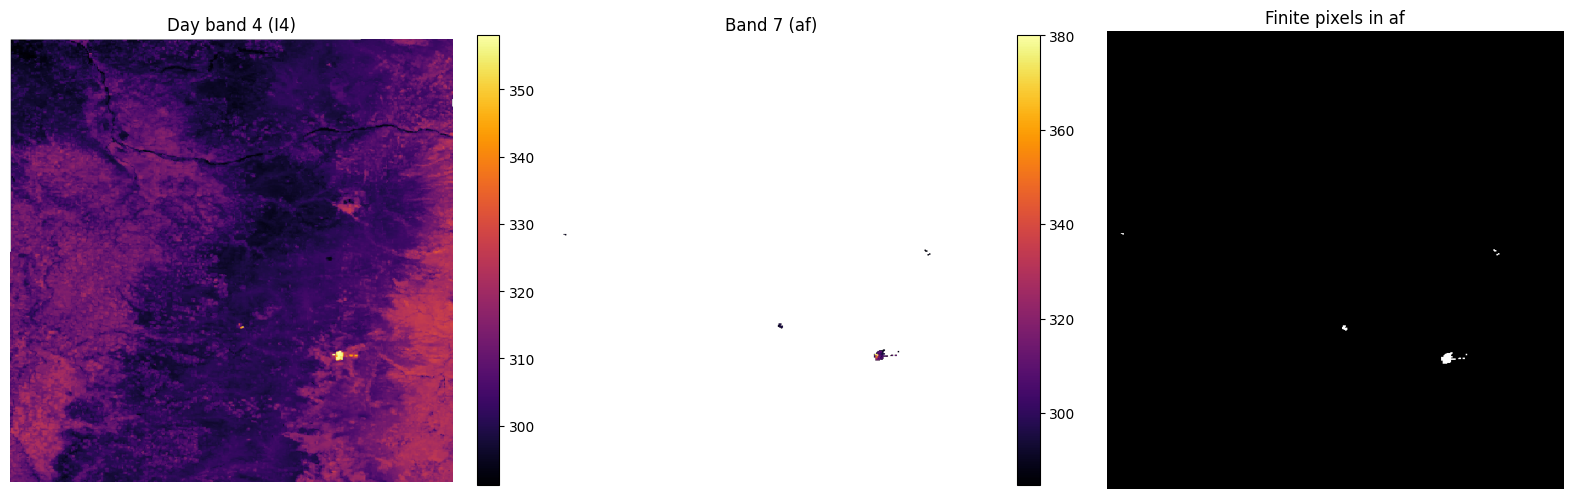

In [10]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

with rasterio.open(day_path) as src:
    af = src.read(7).astype(np.float32)
    i4 = src.read(4).astype(np.float32)

valid_af = np.isfinite(af)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(i4, cmap="inferno")
axes[0].set_title("Day band 4 (I4)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(af, cmap="inferno")
axes[1].set_title("Band 7 (af)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(valid_af, cmap="gray")
axes[2].set_title("Finite pixels in af")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [13]:

import requests

url = (
    "https://raw.githubusercontent.com/zhaoyutim/TS-SatFire/"
    "main/satimg_dataset_processor/satimg_dataset_processor.py"
)

response = requests.get(url, timeout=30)
print("HTTP status:", response.status_code)

if response.ok:
    source = response.text
    lines = source.splitlines()

    keywords = ["AFTestDatasetProcessor", "active_fire", "usecase", "isnan", "isfinite"]
    matches = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]

    shown = set()
    for i in matches:
        for j in range(max(0, i - 3), min(len(lines), i + 5)):
            if j not in shown:
                print(f"{j + 1}: {lines[j]}")
                shown.add(j)
        print("-" * 50)
else:
    print("Could not retrieve the source. Check internet access in Kaggle.")


HTTP status: 200
7: from satimg_dataset_processor.utils import SatProcessingUtils
8: 
9: class AFBADatasetProcessor(SatProcessingUtils):
10:     def dataset_generator_seqtoseq(self, mode, usecase, data_path, locations, file_name, label_name, save_path, rs_idx=0, cs_idx=0,
11:                                                visualize=True, ts_length=10, interval=3, image_size=(224, 224)):
12:         satellite_day = 'VIIRS_Day'
13:         stack_over_location = []
14:         stack_label_over_locations = []
--------------------------------------------------
66:                     img = np.concatenate((array_day[:6, offset:output_shape_x+offset, offset:output_shape_y+offset], array_night[:, offset:output_shape_x+offset, offset:output_shape_y+offset]), axis=0)
67:                     img = np.nan_to_num(img[:,:output_shape_x, :output_shape_y])
68:                     max_img = np.maximum(img, max_img)
69:                     if usecase=='ba':
70:                         print('usecase ba'

In [14]:

# Reuse the source downloaded in your previous cell.
# If `source` still exists, no second download is needed.

lines = source.splitlines()

print("========== SEQUENCE DATASET PROCESSOR ==========")
for i in range(0, min(115, len(lines))):
    print(f"{i + 1}: {lines[i]}")

print("\n========== AF TEST DATASET PROCESSOR ==========")
start = 254  # line 255, zero-based index
end = min(425, len(lines))

for i in range(start, end):
    print(f"{i + 1}: {lines[i]}")


========== SEQUENCE DATASET PROCESSOR ==========
1: import os
2: from glob import glob
3: 
4: import matplotlib.pyplot as plt
5: import numpy as np
6: 
7: from satimg_dataset_processor.utils import SatProcessingUtils
8: 
9: class AFBADatasetProcessor(SatProcessingUtils):
10:     def dataset_generator_seqtoseq(self, mode, usecase, data_path, locations, file_name, label_name, save_path, rs_idx=0, cs_idx=0,
11:                                                visualize=True, ts_length=10, interval=3, image_size=(224, 224)):
12:         satellite_day = 'VIIRS_Day'
13:         stack_over_location = []
14:         stack_label_over_locations = []
15:         n_channels = 8
16:         if not os.path.exists(save_path):
17:             os.mkdir(save_path)
18:         for location in locations:
19:             print(location)
20:             study_area_path = data_path + '/' + location + '/' + satellite_day + '/'
21:             file_list = glob(study_area_path + '/*.tif')
22:             file_lis

In [15]:

import numpy as np
import rasterio
from pathlib import Path

# Use one event from the official AF test processor's threshold dictionary.
event_id = "mosquito_fire"

event_root = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
) / event_id

day_dir = event_root / "VIIRS_Day"
night_dir = event_root / "VIIRS_Night"

day_files = sorted(day_dir.glob("*.tif"))
night_lookup = {p.name: p for p in night_dir.glob("*.tif")}

print("Day files:", len(day_files))
print("Night files:", len(night_lookup))
print("First day file:", day_files[0] if day_files else "NOT FOUND")


Day files: 10
Night files: 10
First day file: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/mosquito_fire/VIIRS_Day/2022-09-03_VIIRS_Day.tif


In [17]:

import numpy as np
import rasterio

day_path = day_files[0]

# Match by date, not by the full filename
night_name = day_path.name.replace("VIIRS_Day", "VIIRS_Night")
night_path = night_dir / night_name

print("Day:", day_path)
print("Night:", night_path)
print("Night exists:", night_path.exists())

if night_path.exists():
    with rasterio.open(day_path) as src:
        day = src.read().astype(np.float32)
        print("Day bands:", src.count, src.descriptions)

    with rasterio.open(night_path) as src:
        night = src.read().astype(np.float32)
        print("Night bands:", src.count, src.descriptions)

    for i in [3, 4, 6]:
        band = day[i]
        valid = np.isfinite(band)
        print(
            f"Day band {i+1}: finite={valid.sum()}, "
            f"min={np.nanmin(band):.2f}, max={np.nanmax(band):.2f}"
        )

    for i in [0, 1]:
        band = night[i]
        valid = np.isfinite(band)
        print(
            f"Night band {i+1}: finite={valid.sum()}, "
            f"min={np.nanmin(band):.2f}, max={np.nanmax(band):.2f}"
        )
else:
    print("No exact date match. Available night filenames:")
    for p in sorted(night_dir.glob("*.tif"))[:10]:
        print(p.name)


Day: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/mosquito_fire/VIIRS_Day/2022-09-03_VIIRS_Day.tif
Night: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/mosquito_fire/VIIRS_Night/2022-09-03_VIIRS_Night.tif
Night exists: True
Day bands: 8 ('b1', 'b2', 'b3', 'b4', 'b5', 'm11', 'af', 'first')
Night bands: 2 ('b1', 'b2')
Day band 4: finite=352836, min=291.65, max=335.83
Day band 5: finite=352836, min=289.72, max=325.48
Day band 7: finite=0, min=nan, max=nan
Night band 1: finite=352836, min=275.98, max=310.62
Night band 2: finite=352836, min=276.39, max=296.98


/tmp/ipykernel_49/1700202395.py:28: RuntimeWarning: All-NaN slice encountered
  f"min={np.nanmin(band):.2f}, max={np.nanmax(band):.2f}"


In [18]:

import numpy as np
import rasterio
import pandas as pd

rows = []

for day_path in day_files:
    with rasterio.open(day_path) as src:
        af = src.read(7).astype(np.float32)
        thermal4 = src.read(4).astype(np.float32)
        thermal5 = src.read(5).astype(np.float32)

    night_path = night_dir / day_path.name.replace(
        "VIIRS_Day", "VIIRS_Night"
    )

    night_finite = 0
    if night_path.exists():
        with rasterio.open(night_path) as src:
            night = src.read().astype(np.float32)
            night_finite = int(np.isfinite(night[:2]).sum())

    rows.append({
        "date": day_path.name[:10],
        "af_finite_pixels": int(np.isfinite(af).sum()),
        "af_positive_pixels": int(
            (np.isfinite(af) & (af > 0)).sum()
        ),
        "day_band4_finite": int(np.isfinite(thermal4).sum()),
        "day_band5_finite": int(np.isfinite(thermal5).sum()),
        "night_finite_values": night_finite,
    })

display(pd.DataFrame(rows))


,date,af_finite_pixels,af_positive_pixels,day_band4_finite,day_band5_finite,night_finite_values
0,2022-09-03,0,0,352836,352836,705672
1,2022-09-04,0,0,352836,352836,705672
2,2022-09-05,0,0,352836,352836,705672
3,2022-09-06,0,0,352836,352836,705672
4,2022-09-07,0,0,352836,352836,705672
5,2022-09-08,0,0,352836,352836,705672
6,2022-09-09,0,0,352836,352836,705672
7,2022-09-10,0,0,352836,352836,705672
8,2022-09-11,0,0,352836,352836,705672
9,2022-09-12,0,0,352836,352836,705672


In [22]:

from pathlib import Path
import numpy as np
import rasterio
import pandas as pd

root = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

# Reuse the test event IDs from your existing split.
# If your variable has another name, replace `test_events` below.
rows = []

for event_id in test_events:
    day_dir = root / str(event_id) / "VIIRS_Day"
    day_files_event = sorted(day_dir.glob("*.tif"))

    total_pixels = 0
    valid_af_pixels = 0
    dates_with_valid_af = 0

    for path in day_files_event:
        with rasterio.open(path) as src:
            af = src.read(7)

        valid = np.isfinite(af)
        total_pixels += af.size
        valid_af_pixels += int(valid.sum())

        if valid.any():
            dates_with_valid_af += 1

    rows.append({
        "event": str(event_id),
        "day_files": len(day_files_event),
        "valid_af_pixels": valid_af_pixels,
        "total_pixels": total_pixels,
        "dates_with_valid_af": dates_with_valid_af,
    })

audit = pd.DataFrame(rows)
display(audit)


,event,day_files,valid_af_pixels,total_pixels,dates_with_valid_af
0,20568194,38,5455,13452912,37
1,20777134,51,53246,18085620,51
2,21038333,14,3279,4956336,14
3,21158939,16,12466,5673920,16
4,21693566,20,0,7080480,0
5,21804884,10,2657,3546200,10
6,21890502,43,30213,15248660,43
7,21998313,24,4047,8510880,23
8,21999381,18,1580,6383160,16
9,22712904,16,0,5664384,0


In [23]:

import rasterio
import numpy as np
from pathlib import Path

root = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

samples = [
    ("labeled_event", "20568194", "2020-09-04"),
    ("zero_af_event", "mosquito_fire", "2022-09-03"),
]

for name, event_id, date in samples:
    path = root / event_id / "VIIRS_Day" / f"{date}_VIIRS_Day.tif"

    if not path.exists():
        print(f"{name}: file not found: {path}")
        continue

    with rasterio.open(path) as src:
        print(f"\n{name}: {path.name}")

        for band_index in (7, 8):
            arr = src.read(band_index)
            finite = np.isfinite(arr)
            values = arr[finite]

            print(
                f"Band {band_index} ({src.descriptions[band_index - 1]}): "
                f"finite={finite.sum()}, "
                f"unique finite values={len(np.unique(values)) if values.size else 0}, "
                f"min={values.min() if values.size else np.nan}, "
                f"max={values.max() if values.size else np.nan}"
            )


labeled_event: file not found: /kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire/20568194/VIIRS_Day/2020-09-04_VIIRS_Day.tif

zero_af_event: 2022-09-03_VIIRS_Day.tif
Band 7 (af): finite=0, unique finite values=0, min=nan, max=nan
Band 8 (first): finite=15, unique finite values=14, min=57476.0, max=57745.0


In [24]:

from pathlib import Path
import rasterio
import numpy as np

root = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

event_id = "20568194"
day_dir = root / event_id / "VIIRS_Day"
day_files = sorted(day_dir.glob("*.tif"))

print("Number of day files:", len(day_files))

if day_files:
    path = day_files[0]
    print("Selected file:", path.name)

    with rasterio.open(path) as src:
        print("Band descriptions:", src.descriptions)

        for i, description in enumerate(src.descriptions, start=1):
            arr = src.read(i)
            finite = np.isfinite(arr)
            values = arr[finite]

            print(
                f"Band {i} ({description}): "
                f"finite={finite.sum()}/{arr.size}, "
                f"min={values.min() if values.size else np.nan}, "
                f"max={values.max() if values.size else np.nan}"
            )
else:
    print("No TIFF files found. Check the event folder path.")


Number of day files: 38
Selected file: 2017-04-08_VIIRS_Day.tif
Band descriptions: ('b1', 'b2', 'b3', 'b4', 'b5', 'm11', 'af', 'first')
Band 1 (b1): finite=352836/354024, min=3.298640251159668, max=58.227996826171875
Band 2 (b2): finite=352836/354024, min=1.231492280960083, max=69.56332397460938
Band 3 (b3): finite=352836/354024, min=0.11595220118761063, max=63.36587905883789
Band 4 (b4): finite=352836/354024, min=263.8891906738281, max=356.5386047363281
Band 5 (b5): finite=352836/354024, min=238.11314392089844, max=314.19384765625
Band 6 (m11): finite=352836/354024, min=0.06397362798452377, max=46.005035400390625
Band 7 (af): finite=67/354024, min=279.0799865722656, max=313.9100036621094
Band 8 (first): finite=0/354024, min=nan, max=nan


In [25]:

# Search the official TS-SatFire processor source
keywords = [
    "af = array_day[6",
    "output_label[j,2",
    "AFTestDatasetProcessor",
    "th_i",
    "af_img",
    "np.logical_or",
]

for keyword in keywords:
    print(f"\n{'=' * 20} {keyword} {'=' * 20}")
    start = 0
    found = False

    while True:
        idx = source.find(keyword, start)
        if idx == -1:
            break
        found = True
        print(source[max(0, idx - 250):idx + 500])
        start = idx + len(keyword)

    if not found:
        print("Not found in source.")



==================== af = array_day[6 ====================
Not found in source.

==================== output_label[j,2 ====================
Not found in source.

==================== AFTestDatasetProcessor ====================
nanstd(dataset_stacked_over_locations[:,i,:,:,:]))
        np.save(save_path + '/' + file_name, dataset_stacked_over_locations.astype(np.float32))
        np.save(save_path + '/' + label_name, labels_stacked_over_locations.astype(np.float32))

class AFTestDatasetProcessor(SatProcessingUtils):  
    def af_test_dataset_generator(self, location, file_name, save_path, image_size=(256, 256)):
        satellite = 'VIIRS_Day'
        window_size = 3
        ts_length = 10
        n_channels = 8
        if not os.path.exists(save_path):
            os.mkdir(save_path)
        print(location)
        data_path = 'data/' + location + '/' + satellite + '/'
        file_list = glob(data_path + '/*.tif')
        file_list.sort()
        if len(file_lis

====================

In [26]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

def audit_af_coverage(event_ids, split_name, crop_offset=128, crop_size=256):
    rows = []

    y0, x0 = crop_offset, crop_offset
    y1, x1 = y0 + crop_size, x0 + crop_size

    for event_id in event_ids:
        event_root = TS_ROOT / str(event_id)
        day_dir = event_root / "VIIRS_Day"

        files = sorted(day_dir.glob("*_VIIRS_Day.tif"))

        valid_pixels = 0
        total_pixels = 0
        positive_pixels = 0
        empty_dates = 0

        for path in files:
            with rasterio.open(path) as src:
                af = src.read(7).astype(np.float32)

            crop = af[y0:y1, x0:x1]
            valid = np.isfinite(crop)

            valid_pixels += int(valid.sum())
            total_pixels += crop.size
            positive_pixels += int((valid & (crop > 0)).sum())

            if not valid.any():
                empty_dates += 1

        rows.append({
            "split": split_name,
            "event": str(event_id),
            "dates": len(files),
            "dates_all_af_nan": empty_dates,
            "valid_af_pixels": valid_pixels,
            "crop_pixels": total_pixels,
            "valid_pixel_fraction": (
                valid_pixels / total_pixels
                if total_pixels else np.nan
            ),
            "positive_af_pixels": positive_pixels,
        })

    return rows

coverage_rows = []
coverage_rows += audit_af_coverage(train_events, "train")
coverage_rows += audit_af_coverage(val_events, "validation")
coverage_rows += audit_af_coverage(test_events, "test")

coverage_df = pd.DataFrame(coverage_rows)

display(
    coverage_df.sort_values(
        ["split", "valid_pixel_fraction"]
    ).reset_index(drop=True)
)

print("\nSummary by split:")
display(
    coverage_df.groupby("split").agg(
        events=("event", "count"),
        dates=("dates", "sum"),
        dates_all_af_nan=("dates_all_af_nan", "sum"),
        valid_af_pixels=("valid_af_pixels", "sum"),
        crop_pixels=("crop_pixels", "sum"),
        positive_af_pixels=("positive_af_pixels", "sum"),
    )
)


,split,event,dates,dates_all_af_nan,valid_af_pixels,crop_pixels,valid_pixel_fraction,positive_af_pixels
0,test,21693566,20,20,0,1310720,0.000000,0
1,test,22712904,16,16,0,1048576,0.000000,0
2,test,22712973,23,23,0,1507328,0.000000,0
3,test,calfcanyon_fire,10,10,0,655360,0.000000,0
4,test,mosquito_fire,10,10,0,655360,0.000000,0
...,...,...,...,...,...,...,...,...
141,validation,21158932,14,3,6929,917504,0.007552,6929
142,validation,21998230,15,2,7810,983040,0.007945,7810
143,validation,24462819,24,0,17381,1572864,0.011051,17381
144,validation,24332732,23,1,17145,1507328,0.011374,17145



Summary by split:


,events,dates,dates_all_af_nan,valid_af_pixels,crop_pixels,positive_af_pixels
split,,,,,,
test,24,593,174,132684,38862848,132684
train,101,2301,524,716720,150798336,716720
validation,21,436,69,141365,28573696,141365


In [27]:
from pathlib import Path
import numpy as np
import rasterio

DATA_ROOT = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

def inspect_af_event(event_id, max_dates=3):
    event_dir = DATA_ROOT / event_id
    day_dir = event_dir / "VIIRS_Day"

    files = sorted(day_dir.glob("*_VIIRS_Day.tif"))
    print(f"\nEvent: {event_id}")

    for path in files[:max_dates]:
        with rasterio.open(path) as src:
            af = src.read(7).astype(np.float32)
            thermal_4 = src.read(4).astype(np.float32)
            thermal_5 = src.read(5).astype(np.float32)

        valid = np.isfinite(af)
        positive = valid & (af > 0)

        print(f"\nDate: {path.name}")
        print(f"AF valid pixels: {valid.sum():,}")
        print(f"AF positive pixels: {positive.sum():,}")
        print(f"AF NaN fraction: {(~valid).mean():.4f}")
        print(
            "Thermal band 4 finite fraction:",
            f"{np.isfinite(thermal_4).mean():.4f}"
        )
        print(
            "Thermal band 5 finite fraction:",
            f"{np.isfinite(thermal_5).mean():.4f}"
        )

inspect_af_event("mosquito_fire")
inspect_af_event("20568194")


Event: mosquito_fire

Date: 2022-09-03_VIIRS_Day.tif
AF valid pixels: 0
AF positive pixels: 0
AF NaN fraction: 1.0000
Thermal band 4 finite fraction: 0.9966
Thermal band 5 finite fraction: 0.9966

Date: 2022-09-04_VIIRS_Day.tif
AF valid pixels: 0
AF positive pixels: 0
AF NaN fraction: 1.0000
Thermal band 4 finite fraction: 0.9966
Thermal band 5 finite fraction: 0.9966

Date: 2022-09-05_VIIRS_Day.tif
AF valid pixels: 0
AF positive pixels: 0
AF NaN fraction: 1.0000
Thermal band 4 finite fraction: 0.9966
Thermal band 5 finite fraction: 0.9966

Event: 20568194

Date: 2017-04-08_VIIRS_Day.tif
AF valid pixels: 67
AF positive pixels: 67
AF NaN fraction: 0.9998
Thermal band 4 finite fraction: 0.9966
Thermal band 5 finite fraction: 0.9966

Date: 2017-04-09_VIIRS_Day.tif
AF valid pixels: 63
AF positive pixels: 63
AF NaN fraction: 0.9998
Thermal band 4 finite fraction: 0.9966
Thermal band 5 finite fraction: 0.9966

Date: 2017-04-10_VIIRS_Day.tif
AF valid pixels: 140
AF positive pixels: 140
AF Na

,dates,total_positive_pixels,mean_positive_fraction,dates_with_no_detections
event,,,,
calfcanyon_fire,10,440,0.000671,1
lytton_fire,10,1029,0.001570,1
mosquito_fire,10,2912,0.004443,4


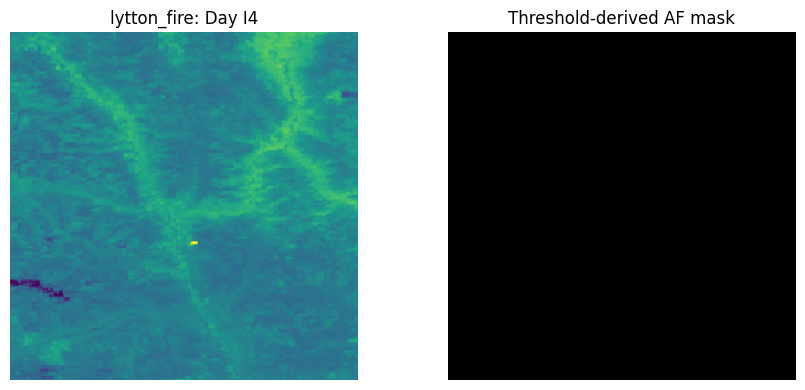

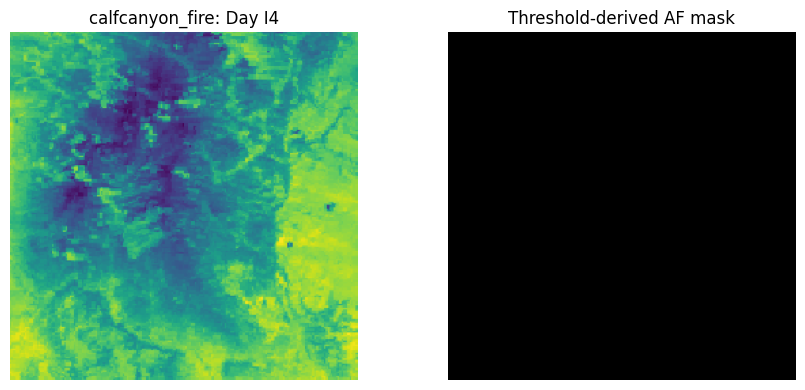

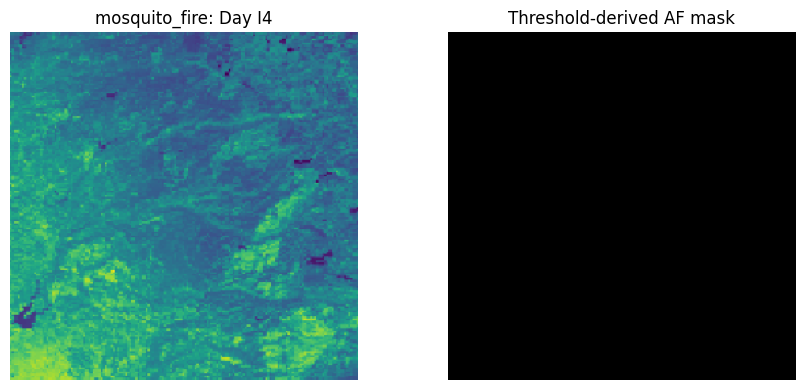

Saved audit: /kaggle/working/ts_satfire_official_style_af_audit.csv


In [28]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

DATA_ROOT = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

# Threshold pairs: (day I4, day I5) and (night band 1, night band 2).
# Order follows the official processor's per-10-image sequence.
THRESHOLDS = {
    "lytton_fire": {
        "day": [(357,330),(340,337),(340,325),(335,330),(337,330),
                (340,330),(360,335),(340,330),(345,330),(340,330)],
        "night": [(320,320),(310,305),(320,305),(315,305),(305,305),
                  (308,305),(300,305),(300,305),(305,305),(304,305)],
    },
    "calfcanyon_fire": {
        "day": [(330,330),(330,337),(330,325),(340,330),(330,330),
                (330,330),(330,330),(330,330),(330,330),(329,330)],
        "night": [(300,320),(320,305),(320,305),(300,300),(305,305),
                  (300,305),(305,305),(300,305),(310,305),(310,305)],
    },
    "mosquito_fire": {
        "day": [(335,330),(335,337),(335,325),(340,330),(340,330),
                (335,330),(330,330),(325,330),(330,330),(335,330)],
        "night": [(300,320),(320,305),(320,305),(315,305),(310,305),
                  (310,305),(305,305),(300,305),(310,305),(315,305)],
    },
}

def centered_crop(arr, size=256):
    h, w = arr.shape[-2:]
    r0 = h // 2 - size // 2
    c0 = w // 2 - size // 2
    return arr[..., r0:r0+size, c0:c0+size]

def make_official_style_mask(event_id, day_path, sequence_index):
    event_thresholds = THRESHOLDS[event_id]
    # Official thresholds cycle by position within each 10-date sequence.
    i = sequence_index % 10

    night_path = Path(
        str(day_path).replace("VIIRS_Day", "VIIRS_Night")
    )

    with rasterio.open(day_path) as src:
        day_i4 = src.read(4).astype(np.float32)
        day_i5 = src.read(5).astype(np.float32)

    with rasterio.open(night_path) as src:
        night_1 = src.read(1).astype(np.float32)
        night_2 = src.read(2).astype(np.float32)

    th_i4, th_i5 = event_thresholds["day"][i]
    th_n1, th_n2 = event_thresholds["night"][i]

    day_mask = (
        (day_i4 > th_i4) | (day_i5 > th_i5)
    )
    night_mask = (
        (night_1 > th_n1) | (night_2 > th_n2)
    )

    # Missing thermal measurements must not trigger a detection.
    day_valid = np.isfinite(day_i4) | np.isfinite(day_i5)
    night_valid = np.isfinite(night_1) | np.isfinite(night_2)
    day_mask &= day_valid
    night_mask &= night_valid

    combined = day_mask | night_mask
    return centered_crop(combined.astype(np.uint8))

rows = []
mask_examples = {}

for event_id in THRESHOLDS:
    day_dir = DATA_ROOT / event_id / "VIIRS_Day"
    files = sorted(day_dir.glob("*_VIIRS_Day.tif"))

    if not files:
        print(f"WARNING: no day TIFFs found for {event_id}")
        continue

    for idx, day_path in enumerate(files):
        mask = make_official_style_mask(event_id, day_path, idx)
        rows.append({
            "event": event_id,
            "date": day_path.name,
            "sequence_position": idx % 10,
            "positive_pixels": int(mask.sum()),
            "crop_pixels": int(mask.size),
            "positive_fraction": float(mask.mean()),
        })

        if idx == 0:
            with rasterio.open(day_path) as src:
                thermal = centered_crop(src.read(4).astype(np.float32))
            mask_examples[event_id] = (thermal, mask)

mask_audit_df = pd.DataFrame(rows)

display(
    mask_audit_df.groupby("event").agg(
        dates=("date", "count"),
        total_positive_pixels=("positive_pixels", "sum"),
        mean_positive_fraction=("positive_fraction", "mean"),
        dates_with_no_detections=(
            "positive_pixels",
            lambda x: int((x == 0).sum())
        ),
    )
)

for event_id, (thermal, mask) in mask_examples.items():
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(thermal)
    axes[0].set_title(f"{event_id}: Day I4")
    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Threshold-derived AF mask")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

audit_path = "/kaggle/working/ts_satfire_official_style_af_audit.csv"
mask_audit_df.to_csv(audit_path, index=False)
print("Saved audit:", audit_path)


In [29]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

DATA_ROOT = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

rows = []

for event_id, config in THRESHOLDS.items():
    files = sorted(
        (DATA_ROOT / event_id / "VIIRS_Day").glob("*_VIIRS_Day.tif")
    )

    for idx, path in enumerate(files):
        i = idx % 10
        th4, th5 = config["day"][i]

        with rasterio.open(path) as src:
            b4 = src.read(4).astype(np.float32)
            b5 = src.read(5).astype(np.float32)

        valid4 = np.isfinite(b4)
        valid5 = np.isfinite(b5)

        detect4 = valid4 & (b4 > th4)
        detect5 = valid5 & (b5 > th5)
        detect_union = detect4 | detect5

        crop4 = centered_crop(b4)
        crop5 = centered_crop(b5)
        crop_valid4 = np.isfinite(crop4)
        crop_valid5 = np.isfinite(crop5)

        crop_detect = (
            (crop_valid4 & (crop4 > th4))
            | (crop_valid5 & (crop5 > th5))
        )

        rows.append({
            "event": event_id,
            "date": path.name,
            "threshold_b4": th4,
            "threshold_b5": th5,
            "b4_min": np.nanmin(b4),
            "b4_p99": np.nanpercentile(b4, 99),
            "b4_max": np.nanmax(b4),
            "b5_min": np.nanmin(b5),
            "b5_p99": np.nanpercentile(b5, 99),
            "b5_max": np.nanmax(b5),
            "b4_pixels_above": int(detect4.sum()),
            "b5_pixels_above": int(detect5.sum()),
            "union_pixels_full": int(detect_union.sum()),
            "union_pixels_crop": int(crop_detect.sum()),
        })

threshold_debug_df = pd.DataFrame(rows)

display(threshold_debug_df)


,event,date,threshold_b4,threshold_b5,b4_min,b4_p99,b4_max,b5_min,b5_p99,b5_max,b4_pixels_above,b5_pixels_above,union_pixels_full,union_pixels_crop
0,lytton_fire,2021-06-29_VIIRS_Day.tif,357,330,277.768097,332.009888,358.198456,275.033691,322.967560,380.260803,52,110,136,0
1,lytton_fire,2021-06-30_VIIRS_Day.tif,340,337,208.000015,331.085236,358.173431,267.768707,316.801575,383.852966,1667,280,1781,73
2,lytton_fire,2021-07-01_VIIRS_Day.tif,340,325,277.443298,324.792480,358.053070,272.290375,309.686218,349.961823,493,4,495,246
3,lytton_fire,2021-07-02_VIIRS_Day.tif,335,330,277.005768,327.003998,357.989594,271.926361,314.745209,367.427917,553,27,567,131
4,lytton_fire,2021-07-03_VIIRS_Day.tif,337,330,275.691193,325.456299,357.084381,259.653381,314.831238,354.437164,364,12,365,80
5,lytton_fire,2021-07-04_VIIRS_Day.tif,340,330,257.172424,320.245361,357.712921,235.092834,307.370209,315.787354,75,0,75,8
6,lytton_fire,2021-07-05_VIIRS_Day.tif,360,335,254.992630,317.954559,355.038452,234.970886,303.832184,314.839050,0,0,0,0
7,lytton_fire,2021-07-06_VIIRS_Day.tif,340,330,276.701630,321.917664,357.205841,252.608627,310.099030,318.634369,148,0,148,28
8,lytton_fire,2021-07-07_VIIRS_Day.tif,345,330,253.885315,317.767029,353.011200,219.983627,304.832550,316.971222,34,0,34,0
9,lytton_fire,2021-07-08_VIIRS_Day.tif,340,330,247.702316,321.977295,343.072968,221.220840,309.469879,316.526123,4,0,4,4


In [30]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio

DATA_ROOT = Path(
    "/kaggle/input/datasets/z789456sx/ts-satfire/ts-satfire"
)

def crop256(arr):
    h, w = arr.shape[-2:]
    r, c = h // 2 - 128, w // 2 - 128
    return arr[..., r:r+256, c:c+256]

rows = []

for event_id in ["lytton_fire", "calfcanyon_fire", "mosquito_fire"]:
    files = sorted(
        (DATA_ROOT / event_id / "VIIRS_Day").glob("*_VIIRS_Day.tif")
    )

    for i, day_path in enumerate(files):
        night_path = Path(
            str(day_path).replace("VIIRS_Day", "VIIRS_Night")
        )

        with rasterio.open(day_path) as src:
            day = src.read().astype(np.float32)

        with rasterio.open(night_path) as src:
            night = src.read().astype(np.float32)

        th4, th5 = THRESHOLDS[event_id]["day"][i % 10]
        thn1, thn2 = THRESHOLDS[event_id]["night"][i % 10]

        day_af = (day[3] > th4) | (day[4] > th5)
        night_af = (night[0] > thn1) | (night[1] > thn2)

        # Match official logic: combine day and night, then crop.
        official_style = crop256(
            (day_af | night_af).astype(np.uint8)
        ).astype(bool)

        # Original band-7 labels, kept separate from the new mask.
        band7 = crop256(day[6])
        band7_positive = np.isfinite(band7) & (band7 > 0)

        rows.append({
            "event": event_id,
            "date": day_path.name,
            "threshold_mask_positive": int(official_style.sum()),
            "band7_positive": int(band7_positive.sum()),
            "band7_valid": int(np.isfinite(band7).sum()),
        })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

display(
    comparison_df.groupby("event")[
        ["threshold_mask_positive", "band7_positive", "band7_valid"]
    ].sum()
)


,event,date,threshold_mask_positive,band7_positive,band7_valid
0,lytton_fire,2021-06-29_VIIRS_Day.tif,0,19,19
1,lytton_fire,2021-06-30_VIIRS_Day.tif,86,93,93
2,lytton_fire,2021-07-01_VIIRS_Day.tif,362,648,648
3,lytton_fire,2021-07-02_VIIRS_Day.tif,131,121,121
4,lytton_fire,2021-07-03_VIIRS_Day.tif,207,297,297
5,lytton_fire,2021-07-04_VIIRS_Day.tif,118,233,233
6,lytton_fire,2021-07-05_VIIRS_Day.tif,6,34,34
7,lytton_fire,2021-07-06_VIIRS_Day.tif,38,33,33
8,lytton_fire,2021-07-07_VIIRS_Day.tif,63,87,87
9,lytton_fire,2021-07-08_VIIRS_Day.tif,18,34,34


,threshold_mask_positive,band7_positive,band7_valid
event,,,
calfcanyon_fire,440,0,0
lytton_fire,1029,1599,1599
mosquito_fire,2912,0,0


In [31]:

import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

rows = []

event_id = "lytton_fire"
files = sorted(
    (DATA_ROOT / event_id / "VIIRS_Day").glob("*_VIIRS_Day.tif")
)

for i, day_path in enumerate(files):
    night_path = Path(
        str(day_path).replace("VIIRS_Day", "VIIRS_Night")
    )

    with rasterio.open(day_path) as src:
        day = src.read().astype(np.float32)

    with rasterio.open(night_path) as src:
        night = src.read().astype(np.float32)

    th4, th5 = THRESHOLDS[event_id]["day"][i % 10]
    thn1, thn2 = THRESHOLDS[event_id]["night"][i % 10]

    day_mask = (day[3] > th4) | (day[4] > th5)
    night_mask = (night[0] > thn1) | (night[1] > thn2)
    threshold_mask = crop256((day_mask | night_mask).astype(np.uint8)).astype(bool)

    band7 = crop256(day[6])
    valid = np.isfinite(band7)
    label_mask = valid & (band7 > 0)

    # Compare only pixels with finite band-7 labels.
    tp = int((threshold_mask & label_mask & valid).sum())
    fp = int((threshold_mask & ~label_mask & valid).sum())
    fn = int((~threshold_mask & label_mask & valid).sum())

    rows.append({
        "date": day_path.name,
        "valid_band7_pixels": int(valid.sum()),
        "threshold_positive_on_valid": int((threshold_mask & valid).sum()),
        "band7_positive": int(label_mask.sum()),
        "overlap_tp": tp,
        "threshold_only_fp": fp,
        "band7_only_fn": fn,
    })

agreement_df = pd.DataFrame(rows)
display(agreement_df)

tp = agreement_df["overlap_tp"].sum()
fp = agreement_df["threshold_only_fp"].sum()
fn = agreement_df["band7_only_fn"].sum()

print("Pooled agreement on finite band-7 pixels")
print("TP:", tp, "FP:", fp, "FN:", fn)
print("Precision:", tp / (tp + fp) if tp + fp else float("nan"))
print("Recall:", tp / (tp + fn) if tp + fn else float("nan"))


,date,valid_band7_pixels,threshold_positive_on_valid,band7_positive,overlap_tp,threshold_only_fp,band7_only_fn
0,2021-06-29_VIIRS_Day.tif,19,0,19,0,0,19
1,2021-06-30_VIIRS_Day.tif,93,77,93,77,0,16
2,2021-07-01_VIIRS_Day.tif,648,348,648,348,0,300
3,2021-07-02_VIIRS_Day.tif,121,69,121,69,0,52
4,2021-07-03_VIIRS_Day.tif,297,178,297,178,0,119
5,2021-07-04_VIIRS_Day.tif,233,100,233,100,0,133
6,2021-07-05_VIIRS_Day.tif,34,4,34,4,0,30
7,2021-07-06_VIIRS_Day.tif,33,21,33,21,0,12
8,2021-07-07_VIIRS_Day.tif,87,44,87,44,0,43
9,2021-07-08_VIIRS_Day.tif,34,17,34,17,0,17


Pooled agreement on finite band-7 pixels
TP: 858 FP: 0 FN: 741
Precision: 1.0
Recall: 0.5365853658536586


In [32]:
import urllib.request

url = (
    "https://raw.githubusercontent.com/zhaoyutim/TS-SatFire/"
    "main/satimg_dataset_processor/satimg_dataset_processor.py"
)

source = urllib.request.urlopen(url).read().decode("utf-8")

for keyword in [
    "class AFTestDatasetProcessor",
    "af_test_dataset_generator",
    "th_i",
    "th_n",
]:
    print(f"\n--- {keyword} ---")
    start = source.find(keyword)
    print(source[start:start + 5000] if start >= 0 else "Not found")


--- class AFTestDatasetProcessor ---
class AFTestDatasetProcessor(SatProcessingUtils):  
    def af_test_dataset_generator(self, location, file_name, save_path, image_size=(256, 256)):
        satellite = 'VIIRS_Day'
        window_size = 3
        ts_length = 10
        n_channels = 8
        if not os.path.exists(save_path):
            os.mkdir(save_path)
        print(location)
        data_path = 'data/' + location + '/' + satellite + '/'
        file_list = glob(data_path + '/*.tif')
        file_list.sort()
        if len(file_list) % ts_length != 0:
            num_sequence = len(file_list) // ts_length + 1
        else:
            num_sequence = len(file_list) // ts_length
        array_day, _ = self.read_tiff(file_list[0])

        padding = window_size // 2
        array_stack = []
        th = {
            'elephant_hill_fire': [(340, 330), (340, 337), (330, 330), (335, 330), (325, 330), (330, 330), (330, 330),
        (330, 330), (340, 330), (335, 330)],
            'ea